In [2]:
import pandas as pd
import numpy as np
from cmdstanpy import CmdStanModel
import geopandas as gpd
from libpysal import weights
from sklearn.preprocessing import LabelEncoder
import networkx as nx
import re
from scipy.sparse import diags

In [29]:
df = pd.read_csv('/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/feature_extraction/all_results.csv')

In [4]:
print(df.columns)

Index(['id', 'time_window_start', 'tweets_struct', 'name', 'username',
       'description', 'location', 'public_metrics.followers_count',
       'profile_image_url', 'clean...pool',
       ...
       'Demo_interest_in_politics_Symbol',
       'Demo_interest_in_politics_Speculation', 'Demo_marital_status_Category',
       'Demo_marital_status_Explanation', 'Demo_marital_status_Symbol',
       'Demo_marital_status_Speculation', 'Demo_partisan_loyalties_Category',
       'Demo_partisan_loyalties_Explanation', 'Demo_partisan_loyalties_Symbol',
       'Demo_partisan_loyalties_Speculation'],
      dtype='object', length=227)


In [30]:
df = df[['id', 'time_window_start', 'username', 'Demo_sex_Symbol', 'Demo_age_Symbol', 'Demo_ethnicity_Symbol', 'Demo_highest_educational_qualification_Symbol','Demo_past_vote_vote_choice_in_the_2020_presidential_election_Symbol', 'Demo_interest_in_politics_Symbol', 'Demo_marital_status_Symbol', 'Demo_partisan_loyalties_Symbol','Demo_which_state_of_the_usa_do_they_live_in__Category','Demo_household_income_bracket_Symbol','Belief_opinion_on_declining_share_of_white_people_in_america_Symbol']]

In [32]:
df_filtered

,id,time_window_start,username,Demo_sex_Symbol,Demo_age_Symbol,Demo_ethnicity_Symbol,Demo_highest_educational_qualification_Symbol,Demo_past_vote_vote_choice_in_the_2020_presidential_election_Symbol,Demo_interest_in_politics_Symbol,Demo_marital_status_Symbol,Demo_partisan_loyalties_Symbol,Demo_which_state_of_the_usa_do_they_live_in__Category,Demo_household_income_bracket_Symbol,Belief_opinion_on_declining_share_of_white_people_in_america_Symbol
10,1081532502966239232,2024-03-24 00:00:00+00:00,xxaleb,s1),a2),e1),q1),vpa3),i3),m2),pid3),not from a state in the usa,h2),rab2)
11,1081532502966239232,2024-04-07 00:00:00+00:00,xxaleb,s1,a2,e1,q1,vpa1,i3,m2,pid4,not from a state in the usa,h2,rab2)
12,1081532502966239232,2024-04-21 00:00:00+00:00,xxaleb,s1),a2),e1),q2),vpa1),i3),m2),pid4),usa,h2),rab2)
13,1081532502966239232,2024-05-05 00:00:00+00:00,xxaleb,s1),a2),e1),q2),vpa1),i3),m2),pid3),not from a state in the usa,h1),rab1)
14,1081532502966239232,2024-05-19 00:00:00+00:00,xxaleb,s1),a2),e1),q2),vpa3),i1),m2),pid4),not from a state in the usa,h3),rab3)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23985,142827500,2024-08-25 00:00:00+00:00,ndrwwwww,s1),a3),e1),q2),vpa3),i4),m2),pid3),illinois,h3),rab3)
23986,142827500,2024-09-08 00:00:00+00:00,ndrwwwww,s1),a3),e1),q2),vpa3),i3),m2),pid3),illinois,h4),rab3)
23987,142827500,2024-09-22 00:00:00+00:00,ndrwwwww,s1),a3),e1),q2),vpa3),i3),m2),pid4),illinois,h3),rab2)
23988,142827500,2024-10-06 00:00:00+00:00,ndrwwwww,s1),a3),e1),q2),vpa1),i3),m2),pid4),illinois,h3),rab3


In [31]:
df_filtered = df.dropna()

In [16]:
col1

,Demo_past_vote_vote_choice_in_the_2020_presidential_election_Symbol,Demo_past_vote_vote_choice_in_the_2020_presidential_election_Symbol
10,vpa3),vpa3)
11,vpa1,vpa1
12,vpa1),vpa1)
13,vpa1),vpa1)
14,vpa3),vpa3)
...,...,...
23985,vpa3),vpa3)
23986,vpa3),vpa3)
23987,vpa3),vpa3)
23988,vpa1),vpa1)


In [ ]:
#unify the symbol output format

def clean_column_pattern(value, row_idx=None, col_name=None):
    if pd.isna(value):
        return value
    
    value_str = str(value)
    
    # Pattern: 1+ letters, 1+ digits, optional parenthesis
    match = re.search(r'([a-zA-Z]+\d+)\)?', value_str)
    if match:
        return match.group(1)
    
    
    
    # Log when no pattern match is found so we know which cell was returned unchanged
    print(f"No pattern match at row {row_idx}, column {col_name}: {value_str}")
    return value  # or np.nan if you want to remove non-matches

# Apply to all symbol columns
columns_to_clean = [col for col in df_filtered.columns if '_Symbol' in col]
for col in columns_to_clean:
    df_filtered[col] = pd.Series(
        (clean_column_pattern(val, row_idx=idx, col_name=col) for idx, val in df_filtered[col].items()),
        index=df_filtered.index
    )


/tmp/ipykernel_93287/2803301450.py:18: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  df_filtered[columns_to_clean] = df_filtered[columns_to_clean].applymap(clean_column_pattern)
/tmp/ipykernel_93287/2803301450.py:18: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_filtered[columns_to_clean] = df_filtered[columns_to_clean].applymap(clean_column_pattern)


In [34]:
# clean up state variable
state_abbreviation_mapping = {
    'alabama': 'AL',
    'alaska': 'AK',
    'arizona': 'AZ',
    'arkansas': 'AR',
    'california': 'CA',
    'colorado': 'CO',
    'connecticut': 'CT',
    'delaware': 'DE',
    'florida': 'FL',
    'georgia': 'GA',
    'hawaii': 'HI',
    'idaho': 'ID',
    'illinois': 'IL',
    'indiana': 'IN',
    'iowa': 'IA',
    'kansas': 'KS',
    'kentucky': 'KY',
    'louisiana': 'LA',
    'maine': 'ME',
    'maryland': 'MD',
    'massachusetts': 'MA',
    'michigan': 'MI',
    'minnesota': 'MN',
    'mississippi': 'MS',
    'missouri': 'MO',
    'montana': 'MT',
    'nebraska': 'NE',
    'nevada': 'NV',
    'new hampshire': 'NH',
    'new jersey': 'NJ',
    'new mexico': 'NM',
    'new york': 'NY',
    'north carolina': 'NC',
    'north dakota': 'ND',
    'ohio': 'OH',
    'oklahoma': 'OK',
    'oregon': 'OR',
    'pennsylvania': 'PA',
    'rhode island': 'RI',
    'south carolina': 'SC',
    'south dakota': 'SD',
    'tennessee': 'TN',
    'texas': 'TX',
    'utah': 'UT',
    'vermont': 'VT',
    'virginia': 'VA',
    'washington': 'WA',
    'west virginia': 'WV',
    'wisconsin': 'WI',
    'wyoming': 'WY',
    # Handle the "not specified" cases
    'usa (not a specific state)': 'No State',
    'usa (no specific state identified)': 'No State',
    'usa (the user is from the united states but does not specify a state)': 'No State',
    'usa (the user is from the united states but no specific state is identified)': 'No State',
    'if they do not specify a state, but are still from the united states of america, write "usa"': 'No State',
    'not from a state in the usa': 'No State',
    'not from a state in the usa,': 'No State',
}
df_filtered['state_cleaned'] = df_filtered['Demo_which_state_of_the_usa_do_they_live_in__Category'].apply(lambda x: state_abbreviation_mapping.get(x.strip().lower(), x.strip().capitalize()))
print(df_filtered['state_cleaned'].value_counts(dropna=False))


state_cleaned
Usa             1736
CA              1025
NY               731
FL               585
TX               573
                ... 
Connecticut,       1
Michigan,          1
Ny,                1
Tennessee,         1
Utah,              1
Name: count, Length: 119, dtype: int64


/tmp/ipykernel_93287/1303876017.py:62: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_filtered['state_cleaned'] = df_filtered['Demo_which_state_of_the_usa_do_they_live_in__Category'].apply(lambda x: state_abbreviation_mapping.get(x.strip().lower(), x.strip().capitalize()))


In [ ]:
# further clean up for state variables
STATE_MAPPING = {
    # Standard abbreviations
    'alabama': 'AL', 'alaska': 'AK', 'arizona': 'AZ', 'arkansas': 'AR', 'california': 'CA',
    'colorado': 'CO', 'connecticut': 'CT', 'delaware': 'DE', 'florida': 'FL', 'georgia': 'GA',
    'hawaii': 'HI', 'idaho': 'ID', 'illinois': 'IL', 'indiana': 'IN', 'iowa': 'IA',
    'kansas': 'KS', 'kentucky': 'KY', 'louisiana': 'LA', 'maine': 'ME', 'maryland': 'MD',
    'massachusetts': 'MA', 'michigan': 'MI', 'minnesota': 'MN', 'mississippi': 'MS', 'missouri': 'MO',
    'montana': 'MT', 'nebraska': 'NE', 'nevada': 'NV', 'new hampshire': 'NH', 'new jersey': 'NJ',
    'new mexico': 'NM', 'new york': 'NY', 'north carolina': 'NC', 'north dakota': 'ND', 'ohio': 'OH',
    'oklahoma': 'OK', 'oregon': 'OR', 'pennsylvania': 'PA', 'rhode island': 'RI', 'south carolina': 'SC',
    'south dakota': 'SD', 'tennessee': 'TN', 'texas': 'TX', 'utah': 'UT', 'vermont': 'VT',
    'virginia': 'VA', 'washington': 'WA', 'west virginia': 'WV', 'wisconsin': 'WI', 'wyoming': 'WY',
    'district of columbia': 'DC', 'washington dc': 'DC', 'dc': 'DC',
    'ny,':'NY',  'wa,': 'WA',
    # Handle common variations
    'california,': 'CA', 'new york,': 'NY', 'texas,': 'TX', 'florida,': 'FL', 'illinois,': 'IL',
    'massachusetts,': 'MA', 'michigan,': 'MI', 'minnesota,': 'MN', 'arizona,': 'AZ', 'nevada,': 'NV',
    'tennessee,': 'TN', 'south carolina,': 'SC', 'kansas,': 'KS', 'louisiana,': 'LA', 'maine,': 'ME',
    'connecticut,': 'CT', 'utah,': 'UT', 'idaho,': 'NV',
    
    # Handle parenthetical variations
    'california (ca)': 'CA', 'arizona (az)': 'AZ', 'kansas (ks)': 'KS', 'tennessee (tn)': 'TN',
    'hi (hawaii)': 'HI', 'ma (massachusetts)': 'MA', 'ca (california)': 'CA',
    
    # Handle USA cases
    'usa': 'USA', 'usa,': 'USA', 'usa (no specific state)': 'USA', 'usa (unspecified state)': 'USA',
    'if they do not specify a state, but are still from the united states of america, write "usa"': 'USA',
    'no state': 'USA'
}

def clean_state(state):
    if pd.isna(state):
        return np.nan
    
    state_str = str(state).strip().lower()
    
    # Direct mapping lookup
    if state_str in STATE_MAPPING:
        return STATE_MAPPING[state_str]
    
    # Handle case variations
    if len(state_str) == 2 and state_str.upper() in STATE_MAPPING.values():
        return state_str.upper()
    
    # Try to find partial matches
    for key, value in STATE_MAPPING.items():
        if key in state_str:
            return value
    
    # If no match found, print warning and return original in uppercase
    print(f"No match found: '{state_str}'")
    return state_str.upper()

df_filtered['state_cleaned'] = df_filtered['state_cleaned'].apply(clean_state)

print(len(df_filtered['state_cleaned'].value_counts()))

49


/tmp/ipykernel_93287/97925411.py:64: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_filtered['state_cleaned'] = df_filtered['state_cleaned'].apply(clean_state)


In [36]:
df_filtered = df_filtered[df_filtered['state_cleaned'] != 'USA']

In [38]:
# unique values 
print(df_filtered['Demo_past_vote_vote_choice_in_the_2020_presidential_election_Symbol'].unique())

# counts for each unique value
print(df_filtered['Demo_past_vote_vote_choice_in_the_2020_presidential_election_Symbol'].value_counts(dropna=False))

# number of unique values
print(df_filtered['Demo_past_vote_vote_choice_in_the_2020_presidential_election_Symbol'].nunique(dropna=True))

# print each unique on its own line
for v in sorted(df_filtered['Demo_past_vote_vote_choice_in_the_2020_presidential_election_Symbol'].dropna().unique()):
    print(v)

['vpa2' 'vpa3' 'vpa1' 'vpa6' 'vpa4' 'vpa5']
Demo_past_vote_vote_choice_in_the_2020_presidential_election_Symbol
vpa2    3825
vpa3    3013
vpa1    1454
vpa6     115
vpa4      17
vpa5      13
Name: count, dtype: int64
6
vpa1
vpa2
vpa3
vpa4
vpa5
vpa6


In [20]:
df

,Unnamed: 0,id,time_window_start,username,Demo_sex_Symbol,Demo_age_Symbol,Demo_ethnicity_Symbol,Demo_highest_educational_qualification_Symbol,Demo_past_vote_vote_choice_in_the_2020_presidential_election_Symbol,Demo_interest_in_politics_Symbol,...,Belief_opinion_on_declining_share_of_white_people_in_america_Symbol,state_cleaned,y_cat,y,sex_idx,age_idx,eth_idx,income_idx,state_idx,raw_codes
0,40,1542629834953719810,2024-05-19 00:00:00+00:00,Badash1821,s2,a4,e1,q1,vpa2,i4,...,rab4,OH,rab4,4,2,4,1,3,34,3
1,41,1542629834953719810,2024-06-16 00:00:00+00:00,Badash1821,s2,a4,e1,q1,vpa2,i4,...,rab5,OH,rab5,5,2,4,1,3,34,4
2,43,1542629834953719810,2024-07-14 00:00:00+00:00,Badash1821,s2,a4,e1,q1,vpa2,i4,...,rab4,OH,rab4,4,2,4,1,3,34,3
3,44,1542629834953719810,2024-07-28 00:00:00+00:00,Badash1821,s2,a4,e1,q1,vpa3,i4,...,rab3,OH,rab3,3,2,4,1,2,34,2
4,45,1542629834953719810,2024-08-11 00:00:00+00:00,Badash1821,s2,a4,e1,q1,vpa2,i4,...,rab4,OH,rab4,4,2,4,1,3,34,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8432,23985,142827500,2024-08-25 00:00:00+00:00,ndrwwwww,s1,a3,e1,q2,vpa3,i4,...,rab3,IL,rab3,3,1,3,1,3,14,2
8433,23986,142827500,2024-09-08 00:00:00+00:00,ndrwwwww,s1,a3,e1,q2,vpa3,i3,...,rab3,IL,rab3,3,1,3,1,4,14,2
8434,23987,142827500,2024-09-22 00:00:00+00:00,ndrwwwww,s1,a3,e1,q2,vpa3,i3,...,rab2,IL,rab2,2,1,3,1,3,14,1
8435,23988,142827500,2024-10-06 00:00:00+00:00,ndrwwwww,s1,a3,e1,q2,vpa1,i3,...,rab3,IL,rab3,3,1,3,1,3,14,2


In [42]:
df["Belief_opinion_on_declining_share_of_white_people_in_america_Symbol"] = df["Belief_opinion_on_declining_share_of_white_people_in_america_Symbol"].replace("raa1", "rab1")

In [20]:
df = pd.read_csv('/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/feature_extraction/white_share_result.csv')

In [21]:
df

,Unnamed: 0.1,Unnamed: 0,id,time_window_start,username,Demo_sex_Symbol,Demo_age_Symbol,Demo_ethnicity_Symbol,Demo_highest_educational_qualification_Symbol,Demo_past_vote_vote_choice_in_the_2020_presidential_election_Symbol,...,Belief_opinion_on_declining_share_of_white_people_in_america_Symbol,state_cleaned,y_cat,y,sex_idx,age_idx,eth_idx,income_idx,vote_idx,state_idx
0,0,40,1542629834953719810,2024-05-19 00:00:00+00:00,Badash1821,s2,a4,e1,q1,vpa2,...,rab4,OH,rab4,4,2,4,1,3,2,34
1,1,41,1542629834953719810,2024-06-16 00:00:00+00:00,Badash1821,s2,a4,e1,q1,vpa2,...,rab5,OH,rab5,5,2,4,1,3,2,34
2,2,43,1542629834953719810,2024-07-14 00:00:00+00:00,Badash1821,s2,a4,e1,q1,vpa2,...,rab4,OH,rab4,4,2,4,1,3,2,34
3,3,44,1542629834953719810,2024-07-28 00:00:00+00:00,Badash1821,s2,a4,e1,q1,vpa3,...,rab3,OH,rab3,3,2,4,1,2,3,34
4,4,45,1542629834953719810,2024-08-11 00:00:00+00:00,Badash1821,s2,a4,e1,q1,vpa2,...,rab4,OH,rab4,4,2,4,1,3,2,34
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8432,8432,23985,142827500,2024-08-25 00:00:00+00:00,ndrwwwww,s1,a3,e1,q2,vpa3,...,rab3,IL,rab3,3,1,3,1,3,3,14
8433,8433,23986,142827500,2024-09-08 00:00:00+00:00,ndrwwwww,s1,a3,e1,q2,vpa3,...,rab3,IL,rab3,3,1,3,1,4,3,14
8434,8434,23987,142827500,2024-09-22 00:00:00+00:00,ndrwwwww,s1,a3,e1,q2,vpa3,...,rab2,IL,rab2,2,1,3,1,3,3,14
8435,8435,23988,142827500,2024-10-06 00:00:00+00:00,ndrwwwww,s1,a3,e1,q2,vpa1,...,rab3,IL,rab3,3,1,3,1,3,1,14


In [22]:
df["y"].value_counts().sort_index()


y
0       1
1     243
2    1032
3    2623
4    2830
5    1708
Name: count, dtype: int64

In [28]:
mrp_min = state_preds["pred_mean"].min()
mrp_max = state_preds["pred_mean"].max()
print(f"MRP predicted values range from {mrp_min} to {mrp_max}")

MRP predicted values range from 2.8634083793465757 to 3.208743571619052


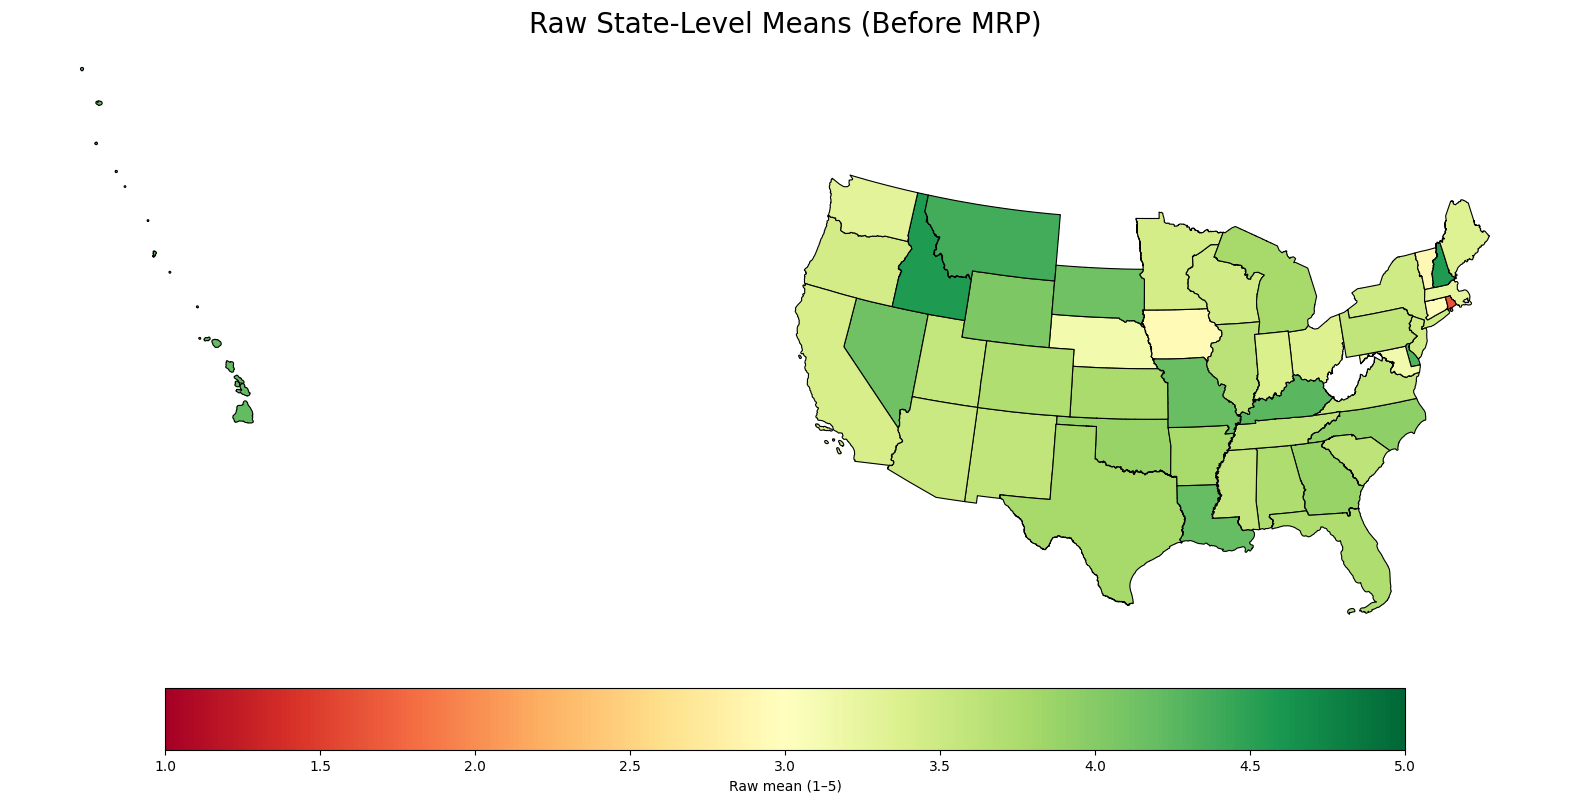

In [30]:
def plot_raw_state_means(df, shp_path, state_col, output_path):

    import geopandas as gpd
    import matplotlib.pyplot as plt

    df["STATE"] = df[state_col].str.upper()

    # Compute raw means
    raw_state_means = (
        df.groupby("STATE")["y"]
          .mean()
          .reset_index()
          .rename(columns={"y": "raw_mean"})
    )

    # Load shapefile
    shp = gpd.read_file(shp_path)
    shp['STATE'] = shp['STUSPS']

    # Merge
    plot_data = shp.merge(raw_state_means, on='STATE', how='inner')

    # Project
    plot_data = plot_data.to_crs('ESRI:102003')

    # Plot
    fig, ax = plt.subplots(figsize=(20, 12))

    plot_data.plot(
        column='raw_mean',
        ax=ax,
        legend=True,
        cmap='RdYlGn',
        vmin=1, vmax=5,
        edgecolor='black',
        linewidth=0.8,
        legend_kwds={
            'label': 'Raw mean (1–5)',
            'orientation': 'horizontal',
            'shrink': 0.8,
            'pad': 0.05
        },
        missing_kwds={'color': 'lightgrey'}
    )

    ax.set_title('Raw State-Level Means (Before MRP)', fontsize=20)
    ax.axis('off')

    plt.savefig(output_path, dpi=300, bbox_inches='tight')
    plt.close()

    return fig
plot_raw_state_means(df, '/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/tl_2025_us_state/tl_2025_us_state.shp', 'state_cleaned','/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/all_n_white_share/raw_state_means.png')

In [ ]:
def plot_raw_state_means(df, shp_path, state_col, output_path):

    import geopandas as gpd
    import matplotlib.pyplot as plt

    df["STATE"] = df[state_col].str.upper()

    # Compute raw means
    raw_state_means = (
        df.groupby("STATE")["y"]
          .mean()
          .reset_index()
          .rename(columns={"y": "raw_mean"})
    )

    # Load shapefile
    shp = gpd.read_file(shp_path)
    shp['STATE'] = shp['STUSPS']

    # Merge
    plot_data = shp.merge(raw_state_means, on='STATE', how='inner')

    # Project
    plot_data = plot_data.to_crs('ESRI:102003')

    # Plot
    fig, ax = plt.subplots(figsize=(20, 12))

    plot_data.plot(
        column='raw_mean',
        ax=ax,
        legend=True,
        cmap='RdYlGn',
        vmin=mrp_min, vmax=mrp_max,
        edgecolor='black',
        linewidth=0.8,
        legend_kwds={
            'label': 'Raw mean (1–5)',
            'orientation': 'horizontal',
            'shrink': 0.8,
            'pad': 0.05
        },
        missing_kwds={'color': 'lightgrey'}
    )

    ax.set_title('Raw State-Level Means (Before MRP)', fontsize=20)
    ax.axis('off')

    plt.savefig(output_path, dpi=300, bbox_inches='tight')
    plt.close()

    return fig
plot_raw_state_means(df, '/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/tl_2025_us_state/tl_2025_us_state.shp', 'state_cleaned','/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/all_n_white_share/raw_state_means.png')

In [ ]:
import re

# Get all columns that start with "Belief" and end with "Symbol"
belief_symbol_cols = [col for col in df.columns if col.startswith('Belief') and col.endswith('Symbol')]

print(f"Found {len(belief_symbol_cols)} Belief Symbol columns\n")

# For each column, extract the letter prefix and check consistency
for col in belief_symbol_cols:
    # Get non-null values
    non_null_values = df[col].dropna()
    
    if len(non_null_values) == 0:
        continue
    
    # Extract letter prefix from each value (letters before digits)
    letter_prefixes = set()
    for idx, val in non_null_values.items():
        match = re.match(r'([a-zA-Z]+)', str(val))
        if match:
            letter_prefixes.add(match.group(1))
    
    # If more than one unique letter prefix, print the inconsistencies
    if len(letter_prefixes) > 1:
        print(f"Column '{col}' has inconsistent letter prefixes: {letter_prefixes}")
        # Print the rows with different prefixes
        for idx, val in non_null_values.items():
            match = re.match(r'([a-zA-Z]+)', str(val))
            if match:
                prefix = match.group(1)
                if prefix != list(letter_prefixes)[0]:
                    print(f"  Row {idx}: {val}")
        print()

print("Sanity check complete!")

In [23]:
df.loc[df["y"] == 0, "Belief_opinion_on_declining_share_of_white_people_in_america_Symbol"].unique()

array(['rab1'], dtype=object)

In [43]:
df.to_csv('/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/feature_extraction/white_share_result.csv')

In [6]:
from sklearn.preprocessing import LabelEncoder

def inspect_encoding(col):
    le = LabelEncoder()
    le.fit(df_filtered[col])
    print(f"\n=== Encoding for {col} ===")
    for i, cat in enumerate(le.classes_, start=1):
        print(f"  {i} → {cat}")
    return le

le_sex    = inspect_encoding("Demo_sex_Symbol")
le_age    = inspect_encoding("Demo_age_Symbol")
le_eth    = inspect_encoding("Demo_ethnicity_Symbol")
le_income = inspect_encoding("Demo_household_income_bracket_Symbol")
le_state  = inspect_encoding("state_cleaned")


NameError: name 'df_filtered' is not defined

In [10]:
strat_frame = pd.read_csv("/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/feature_extraction/cleaned_sf.csv")

In [11]:
print(list(strat_frame.columns))

['Unnamed: 0.1', 'Unnamed: 0', 'state_abbreviation', 'state_simple', 'state_electoral.college', 'region', 'gender', 'ethnicity', 'age_bins', 'college_grad', 'hh_income', 'vote2020', 'vote2022', 'LP_pct.2020.votes.D', 'LP_pct.2020.votes.R', 'LP_pct.2020.votes.L', 'LP_pct.2020.votes.G', 'LP_pct.2020.votes.stay.home', 'LP_pct.2020.votes.OTHER', 'LP_pct.2022.votes.D', 'LP_pct.2022.votes.R', 'LP_pct.2022.votes.L', 'LP_pct.2022.votes.G', 'LP_pct.2022.votes.stay.home', 'LP_pct.2022.votes.OTHER', 'N_star.1', 'N_star.2', 'N_star.3', 'N_star.4', 'N_star.5', 'N_star.6', 'N_star.7', 'N_star.8', 'N_star.9', 'N_star.10', 'N_star.11', 'N_star.12', 'N_star.13', 'N_star.14', 'N_star.15', 'N_star.16', 'N_star.17', 'N_star.18', 'N_star.19', 'N_star.20', 'N_star.21', 'N_star.22', 'N_star.23', 'N_star.24', 'N_star.25', 'N_star.26', 'N_star.27', 'N_star.28', 'N_star.29', 'N_star.30', 'N_star.31', 'N_star.32', 'N_star.33', 'N_star.34', 'N_star.35', 'N_star.36', 'N_star.37', 'N_star.38', 'N_star.39', 'N_star.

In [ ]:
LP_cols =  [
    'LP_pct.2020.votes.D', 'LP_pct.2020.votes.R', 'LP_pct.2020.votes.L',
    'LP_pct.2020.votes.G', 'LP_pct.2020.votes.stay.home', 'LP_pct.2020.votes.OTHER',
    'LP_pct.2022.votes.D', 'LP_pct.2022.votes.R', 'LP_pct.2022.votes.L',
    'LP_pct.2022.votes.G', 'LP_pct.2022.votes.stay.home', 'LP_pct.2022.votes.OTHER'
]

strat_frame = strat_frame.set_index('state_simple')

In [ ]:

def edges_from_adjacency(W):
    all_edges = []
    n = W.shape[0]
    
    for i in range(n):
        neighbors = np.where(W[i, :] != 0)[0]
        for j in neighbors:
            if i < j:  
                all_edges.append({
                    'node1': i + 1,  
                    'node2': j + 1,
                    'weight': W[i, j]
                })
    
    return pd.DataFrame(all_edges)


def scale_c(C):
    N = C.shape[0]
    
    if hasattr(C, 'toarray'):
        C = C.toarray()
    C = np.asarray(C)
    
    row_sums = C.sum(axis=1).ravel()
    Q = diags(row_sums) - C
    
    Q_dense = Q.toarray() if hasattr(Q, 'toarray') else np.asarray(Q)
    max_diag = np.max(np.diag(Q_dense))
    jitter = max_diag * np.sqrt(np.finfo(float).eps)
    Q_pert = Q_dense + np.diag(np.ones(N) * jitter)
    
    Q_inv = np.linalg.pinv(Q_pert)
    
    variances = np.diag(Q_inv)
    scaling_factor = np.exp(np.mean(np.log(variances)))
    
    return scaling_factor


def prep_icar_data_from_weights(w, N_regions):
    C = np.zeros((N_regions, N_regions))
    for i in range(N_regions):
        for j in w.neighbors[i]:
            C[i, j] = 1

    E = edges_from_adjacency(C)
    
    G = nx.Graph()
    G.add_nodes_from(range(N_regions))
    for _, row in E.iterrows():
        G.add_edge(int(row['node1']) - 1, int(row['node2']) - 1)
    
    components = list(nx.connected_components(G))
    k = len(components)
    
    comp_id = np.zeros(N_regions, dtype=int)
    for idx, component in enumerate(components):
        for node in component:
            comp_id[int(node)] = idx
    
    group_size = np.array([len(comp) for comp in components])
    
    group_idx = comp_id + 1
    
    scale_factor = scale_c(C)
    inv_sqrt_scale_factor = np.ones(k) / np.sqrt(scale_factor)
    
    m = np.sum(group_size > 1) - 1
    
    if m > 0:
        main_comp = None
        for i, size in enumerate(group_size):
            if size > 1:
                main_comp = i
                break
        
        comp_id_adjusted = comp_id.copy()
        for i in range(k):
            if group_size[i] == 1:
                comp_id_adjusted[comp_id == i] = main_comp
        
        unique_comps = np.unique(comp_id_adjusted)
        unique_comps = unique_comps[unique_comps != main_comp]
        
        A = np.zeros((N_regions, m))
        for idx, comp in enumerate(unique_comps):
            A[comp_id_adjusted == comp, int(idx)] = 1
    else:
        A = np.zeros((N_regions, 0))
    
    return {
        'k': int(k),
        'group_size': group_size.tolist(),
        'N_edges': len(E),
        'node1': E['node1'].values.tolist(),
        'node2': E['node2'].values.tolist(),
        'group_idx': group_idx.tolist(),
        'm': int(m),
        'A': A.tolist(),
        'inv_sqrt_scale_factor': inv_sqrt_scale_factor.tolist(),
    }


def moran_coefficient(x, W, warn=True):
    row_sums = W.sum(axis=1)
    zero_idx = np.where(row_sums == 0)[0]
    
    if len(zero_idx) > 0:
        if warn:
            print(f"{len(zero_idx)} observations with no neighbors. Dropping from calculation.")
        keep_idx = row_sums > 0
        x = x[keep_idx]
        W = W[np.ix_(keep_idx, keep_idx)]
    
    n = len(x)
    xbar = np.mean(x)
    z = x - xbar
    z_tilde = W @ z
    A = np.sum(W)
    mc = (n / A) * (z @ z_tilde) / (z @ z)
    
    return np.round(mc, 3)


df = pd.read_csv("/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/feature_extraction/white_share_result.csv")

likert_order = ["rab1", "rab2", "rab3", "rab4", "rab5"]
df["y_cat"] = pd.Categorical(
    df["Belief_opinion_on_declining_share_of_white_people_in_america_Symbol"],
    categories=likert_order, ordered=True
)
df["y"] = df["y_cat"].cat.codes + 1
K = len(likert_order)

# Encode categorical predictors
def encode_var(col):
    le = LabelEncoder()
    encoded = le.fit_transform(df[col]) + 1
    n_cats = len(le.classes_)
    print(f"{col}: {n_cats} categories")
    return encoded, n_cats

df["sex_idx"], J_sex = encode_var("Demo_sex_Symbol")
df["age_idx"], J_age = encode_var("Demo_age_Symbol")
df["eth_idx"], J_eth = encode_var("Demo_ethnicity_Symbol")
df["income_idx"], J_income = encode_var("Demo_household_income_bracket_Symbol")
df["vote_idx"], J_vote = encode_var("Demo_past_vote_vote_choice_in_the_2020_presidential_election_Symbol")
df["state_idx"], N_regions = encode_var("state_cleaned")

print(f"\nTotal observations: {len(df)}")
print(f"Number of states: {N_regions}")


# Build spatial structure
shp = gpd.read_file("/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/tl_2025_us_state/tl_2025_us_state.shp")
shp["STATE"] = shp["STUSPS"].str.upper()

states_in_data = df["state_cleaned"].str.upper().unique()
shp = shp[shp["STATE"].isin(states_in_data)]

state_order = sorted(df["state_cleaned"].unique())
shp = shp.set_index("STATE").loc[[s.upper() for s in state_order]].reset_index()

print(f"Shapefile regions: {len(shp)}")

w = weights.Queen.from_dataframe(shp)

icar_data = prep_icar_data_from_weights(w, N_regions)

print(f"\nICAR structure:")
print(f"  Connected components: {icar_data['k']}")
print(f"  Component sizes: {icar_data['group_size']}")
print(f"  Number of edges: {icar_data['N_edges']}")
print(f"  Extra intercepts (m): {icar_data['m']}")
print(f"  Scaling factors: {icar_data['inv_sqrt_scale_factor']}")

# Check spatial autocorrelation in outcome
C = np.zeros((N_regions, N_regions))
for i in range(N_regions):
    for j in w.neighbors[i]:
        C[i, j] = 1

# Aggregate outcome by state for Moran's I
state_means = df.groupby("state_idx")["y"].mean().values
mc_val = moran_coefficient(state_means, C)
print(f"\nMoran's I for state-level outcome: {mc_val}")

strat_frame = pd.read_csv("/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/feature_extraction/cleaned_sf.csv")
LP_cols = [
    'LP_pct.2020.votes.D', 'LP_pct.2020.votes.R', 'LP_pct.2020.votes.L',
    'LP_pct.2020.votes.G', 'LP_pct.2020.votes.stay.home', 'LP_pct.2020.votes.OTHER',
    'LP_pct.2022.votes.D', 'LP_pct.2022.votes.R', 'LP_pct.2022.votes.L',
    'LP_pct.2022.votes.G', 'LP_pct.2022.votes.stay.home', 'LP_pct.2022.votes.OTHER'
]
LP_state = strat_frame.groupby('state_abbreviation')[LP_cols].mean().reset_index()
LP_mat = LP_state.set_index('state_abbreviation').loc[[s.upper() for s in state_order],LP_cols].values
print(LP_mat.shape)

Demo_sex_Symbol: 2 categories
Demo_age_Symbol: 7 categories
Demo_ethnicity_Symbol: 6 categories
Demo_household_income_bracket_Symbol: 5 categories
Demo_past_vote_vote_choice_in_the_2020_presidential_election_Symbol: 6 categories
state_cleaned: 48 categories

Total observations: 8437
Number of states: 48
Shapefile regions: 48


/tmp/ipykernel_1701/3564975358.py:167: FutureWarning: `use_index` defaults to False but will default to True in future. Set True/False directly to control this behavior and silence this warning
  w = weights.Queen.from_dataframe(shp)
/home/yuyue/stan_env/lib/python3.12/site-packages/libpysal/weights/contiguity.py:347: UserWarning: The weights matrix is not fully connected: 
 There are 2 disconnected components.
 There is 1 island with id: 10.
  W.__init__(self, neighbors, ids=ids, **kw)



ICAR structure:
  Connected components: 2
  Component sizes: [47, 1]
  Number of edges: 104
  Extra intercepts (m): 0
  Scaling factors: [0.002273974148637233, 0.002273974148637233]
1 observations with no neighbors. Dropping from calculation.

Moran's I for state-level outcome: 0.124
(48, 12)


In [31]:
LP_mat.shape

(48, 12)

In [20]:
state_order

['AL',
 'AR',
 'AZ',
 'CA',
 'CO',
 'CT',
 'DC',
 'DE',
 'FL',
 'GA',
 'HI',
 'IA',
 'ID',
 'IL',
 'IN',
 'KS',
 'KY',
 'LA',
 'MA',
 'MD',
 'ME',
 'MI',
 'MN',
 'MO',
 'MS',
 'MT',
 'NC',
 'NE',
 'NH',
 'NJ',
 'NM',
 'NV',
 'NY',
 'OH',
 'OK',
 'OR',
 'PA',
 'RI',
 'SC',
 'SD',
 'TN',
 'TX',
 'UT',
 'VA',
 'VT',
 'WA',
 'WI',
 'WY']

In [9]:

# Stan data
stan_data = {
    "N": len(df),
    "K": K,
    "y": df["y"].astype(int).tolist(),
    
    # Predictor dimensions
    "J_sex": J_sex,
    "J_age": J_age,
    "J_eth": J_eth,
    "J_income": J_income,
    "J_vote": J_vote,
    "N_regions": N_regions,
    

    # Predictor indices
    "sex_idx": df["sex_idx"].astype(int).tolist(),
    "age_idx": df["age_idx"].astype(int).tolist(),
    "eth_idx": df["eth_idx"].astype(int).tolist(),
    "income_idx": df["income_idx"].astype(int).tolist(),
    "vote_idx": df["vote_idx"].astype(int).tolist(),
    "state_idx": df["state_idx"].astype(int).tolist(),
    
    # ICAR spatial structure
    **icar_data,

    # state level fix effect
    "P": LP_mat.shape[1],
    "LP": LP_mat.tolist(),
}

print(f"\nStan data prepared with {len(stan_data)} components")



Stan data prepared with 26 components


In [5]:
# Stan code
stan_code = '''
functions {
  real icar_normal_lpdf(vector phi, int N_edges,
                        array[] int node1, array[] int node2) {
    return -0.5 * dot_self(phi[node1] - phi[node2]);
  }
}

data {
  int<lower=1> N;                   
  int<lower=2> K;                 
  array[N] int<lower=1, upper=K> y;

  int<lower=1> J_sex;
  int<lower=1> J_age;
  int<lower=1> J_eth;
  int<lower=1> J_income;
  int<lower=1> J_vote;
  int<lower=1> N_regions;

  array[N] int<lower=1, upper=J_sex> sex_idx;
  array[N] int<lower=1, upper=J_age> age_idx;
  array[N] int<lower=1, upper=J_eth> eth_idx;
  array[N] int<lower=1, upper=J_income> income_idx;
  array[N] int<lower=1, upper=J_vote> vote_idx;
  array[N] int<lower=1, upper=N_regions> state_idx;

  // ICAR structure
  int<lower=1> N_edges;
  array[N_edges] int node1;
  array[N_edges] int node2;

  int<lower=1> k;                           // number of connected components
  array[k] int group_size;                  // size of each connected component
  array[N_regions] int group_idx;           // component assignment for each region
  vector[k] inv_sqrt_scale_factor;          // ICAR variance scale adjustment
  
  // For handling disconnected components
  int<lower=0> m;                           // number of extra intercepts needed
  matrix[N_regions, m] A;                   // constraint matrix for multiple components

  // state level fixed effects
  int<lower=1> P;                           // number of state-level predictors
  matrix[N_regions, P] LP;                  // state-level predictor matrix
}

parameters {
  real alpha;
  ordered[K-1] kappa;

  vector[J_sex-1] eta_sex_tilde;
  vector[J_age-1] eta_age_raw;             
  vector[J_eth-1] eta_eth_tilde;
  vector[J_income-1] eta_income_raw;      
  vector[J_vote-1] eta_vote_tilde;
  vector[N_regions] eta_state_raw;
  vector[P] beta_LP_raw;

  real<lower=0> sigma_sex;
  real<lower=0> sigma_age;
  real<lower=0> sigma_eth;
  real<lower=0> sigma_income;
  real<lower=0> sigma_vote;
  real<lower=0> sigma_state;
  real<lower=0> sigma_LP;
  
  vector[m] alpha_component;                // Extra intercepts for disconnected components
}

transformed parameters {
  vector[J_sex] eta_sex;
  vector[J_age] eta_age;
  vector[J_eth] eta_eth;
  vector[J_income] eta_income;
  vector[J_vote] eta_vote;
  vector[N_regions] eta_state;
  vector[P] beta_LP = sigma_LP * beta_LP_raw;
  vector[N_regions] mu_state_LP = LP * beta_LP; 

  // Hard sum-to-zero constraints for sex, ethnicity, and vote
  for (i in 1:(J_sex-1)) eta_sex[i] = sigma_sex * eta_sex_tilde[i];
  eta_sex[J_sex] = -sum(eta_sex[1:(J_sex-1)]);

  for (i in 1:(J_eth-1)) eta_eth[i] = sigma_eth * eta_eth_tilde[i];
  eta_eth[J_eth] = -sum(eta_eth[1:(J_eth-1)]);

  for (i in 1:(J_vote-1)) eta_vote[i] = sigma_vote * eta_vote_tilde[i];
  eta_vote[J_vote] = -sum(eta_vote[1:(J_vote-1)]);

  // Random walk with hard sum-to-zero for age
  eta_age[1] = sigma_age * eta_age_raw[1];
  for (i in 2:(J_age-1)) {
    eta_age[i] = eta_age[i-1] + sigma_age * eta_age_raw[i];
  }
  // Last category forced to sum to zero
  eta_age[J_age] = -sum(eta_age[1:(J_age-1)]);

  // Random walk with hard sum-to-zero for income
  eta_income[1] = sigma_income * eta_income_raw[1];
  for (i in 2:(J_income-1)) {
    eta_income[i] = eta_income[i-1] + sigma_income * eta_income_raw[i];
  }
  eta_income[J_income] = -sum(eta_income[1:(J_income-1)]);

  // ICAR spatial effects with proper scaling
  for (i in 1:N_regions) {
    int component = group_idx[i];
    eta_state[i] = sigma_state * inv_sqrt_scale_factor[component] * eta_state_raw[i];
  }
  
  // allows disconnected geographic regions to have different baseline levels
  if (m > 0) {
    eta_state = eta_state + A * alpha_component;
  }
}

model {
  // Priors
  alpha ~ normal(0, 2);
  kappa ~ normal(0, 3);
  beta_LP_raw ~ normal(0, 1);

  // Sum-to-zero effects
  eta_sex_tilde ~ normal(0, 1);
  eta_eth_tilde ~ normal(0, 1);
  eta_vote_tilde ~ normal(0, 1);
  
  // Random walk priors 
  eta_age_raw ~ normal(0, 1);
  eta_income_raw ~ normal(0, 1);
  
  sigma_sex ~ normal(0, 1);
  sigma_age ~ normal(0, 1);
  sigma_eth ~ normal(0, 1);
  sigma_income ~ normal(0, 1);
  sigma_vote ~ normal(0, 1);
  sigma_state ~ normal(0, 1);
  sigma_LP ~ normal(0, 1);

  // ICAR prior on raw spatial effects
  target += icar_normal_lpdf(eta_state_raw | N_edges, node1, node2);
  
  // Sum-to-zero constraint per connected component
  for (j in 1:k) {
    real component_sum = 0;
    for (i in 1:N_regions) {
      if (group_idx[i] == j) {
        component_sum += eta_state_raw[i];
      }
    }
    target += normal_lpdf(component_sum | 0, 0.001 * group_size[j]);
  }
  
  // Prior on component intercepts
  if (m > 0) {
    alpha_component ~ normal(0, 1);
  }

  // Ordered logistic
  for (i in 1:N) {
    real mu = alpha
              + eta_sex[sex_idx[i]]
              + eta_age[age_idx[i]]
              + eta_eth[eth_idx[i]]
              + eta_income[income_idx[i]]
              + eta_vote[vote_idx[i]]
              + eta_state[state_idx[i]]
              + mu_state_LP[state_idx[i]];
    y[i] ~ ordered_logistic(mu, kappa);
  }
}

generated quantities {
  vector[N] mu;
  vector[N] log_lik;
  
  for (i in 1:N) {
    mu[i] = alpha
            + eta_sex[sex_idx[i]]
            + eta_age[age_idx[i]]
            + eta_eth[eth_idx[i]]
            + eta_income[income_idx[i]]
            + eta_vote[vote_idx[i]]
            + eta_state[state_idx[i]]
            + mu_state_LP[state_idx[i]];
    log_lik[i] = ordered_logistic_lpmf(y[i] | mu[i], kappa);
  }
}
'''


# Compile and Sample

with open('mrp.stan', 'w') as f:
    f.write(stan_code)

model = CmdStanModel(stan_file='mrp.stan')

fit = model.sample(
    data=stan_data,
    chains=8,
    parallel_chains=8,
    iter_warmup=2000,
    iter_sampling=1000,
    adapt_delta=0.995,
    max_treedepth=13,
    sig_figs=18,
    show_console=True
)

print(fit.summary())

fit.save_csvfiles(dir="/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/white_share_stan_output/mrp_results/")

summary_df = fit.summary()

summary_df.to_csv("/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/white_share_stan_output/mrp_summary.csv", index=True)

posterior_draws = fit.draws_pd()  

posterior_draws.to_csv("/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/white_share_stan_output/mrp_draws.csv", index=False)

18:49:34 - cmdstanpy - INFO - compiling stan file /tmp/tmpwljdqgyb/tmpo3eirntr.stan to exe file /mnt/c/Users/yuyue/AppData/Local/Programs/Microsoft VS Code/mrp
18:49:47 - cmdstanpy - INFO - compiled model executable: /mnt/c/Users/yuyue/AppData/Local/Programs/Microsoft VS Code/mrp
18:49:48 - cmdstanpy - INFO - Chain [1] start processing
18:49:48 - cmdstanpy - INFO - Chain [2] start processing
18:49:48 - cmdstanpy - INFO - Chain [3] start processing
18:49:48 - cmdstanpy - INFO - Chain [4] start processing
18:49:48 - cmdstanpy - INFO - Chain [5] start processing
18:49:48 - cmdstanpy - INFO - Chain [6] start processing
18:49:48 - cmdstanpy - INFO - Chain [7] start processing
18:49:48 - cmdstanpy - INFO - Chain [8] start processing


Chain [6] method = sample (Default)Chain [2] method = sample (Default)

Chain [1] method = sample (Default)
Chain [1] sample
Chain [1] num_samples = 1000 (Default)
Chain [1] num_warmup = 2000
Chain [1] save_warmup = false (Default)
Chain [1] thin = 1 (Default)
Chain [1] adapt
Chain [8] method = sample (Default)
Chain [8] sample
Chain [8] num_samples = 1000 (Default)
Chain [8] num_warmup = 2000
Chain [8] save_warmup = false (Default)
Chain [8] thin = 1 (Default)
Chain [8] adapt
Chain [4] method = sample (Default)
Chain [4] sample
Chain [4] num_samples = 1000 (Default)
Chain [4] num_warmup = 2000
Chain [4] save_warmup = false (Default)
Chain [4] thin = 1 (Default)
Chain [4] adapt
Chain [4] engaged = true (Default)
Chain [4] gamma = 0.05 (Default)
Chain [4] delta = 0.995
Chain [4] kappa = 0.75 (Default)
Chain [4] t0 = 10 (Default)
Chain [4] init_buffer = 75 (Default)
Chain [4] term_buffer = 50 (Default)
Chain [4] window = 25 (Default)
Chain [4] save_metric = false (Default)
Chain [4] algo

22:17:09 - cmdstanpy - INFO - Chain [8] done processing


Chain [8] 
Chain [8] Elapsed Time: 8838.86 seconds (Warm-up)
Chain [8] 3337.73 seconds (Sampling)
Chain [8] 12176.6 seconds (Total)
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 

22:42:26 - cmdstanpy - INFO - Chain [1] done processing


Chain [1] 
Chain [1] Elapsed Time: 9354.7 seconds (Warm-up)
Chain [1] 4310.32 seconds (Sampling)
Chain [1] 13665 seconds (Total)
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [1] 
Chain [7] Iteration: 2600 / 3000 [ 86%]  (Sampling)
Chain [5] Iteration: 2500 / 3000 [ 83%]  (Sampling)
Chain [3] Iteration: 2600 / 3000 [ 86%]  (Sampling)
Chain [2] Iteration: 2600 / 3000 [ 86%]  (Sampling)
Chain [4] Iteration: 2700 / 3000 [ 90%]  (Sampling)
Chain [6] Iteration: 2700 / 3000 [ 90%]  (Sampling)
Chain [7] Iteration: 2700 / 3000 [ 90%]  (Sampling)
Chain [5] Iteration: 2600 / 3000 [ 86%]  (Sampling)
Chain [3] Iteration: 2700 / 3000 [ 90%]  (Sampling)
Chain [4] Iteration: 2800 / 3000 [ 93%]  (Sampling)
Chain [2] Iteration: 2700 / 3000 [ 90%]  (Sampling)
Chain [6] Iteration: 2800 / 3000 [ 93%]  (Sampling)
Chain [7] Iteration: 2800 / 3000 [ 93%]  (Samplin

... (10 outputs left out)

23:32:57 - cmdstanpy - INFO - Chain [5] done processing
23:32:57 - cmdstanpy - WARNING - Non-fatal error during sampling:
Exception: ordered_logistic: Location parameter is inf, but must be finite! (in 'mrp.stan', line 169, column 4 to column 39)
	Exception: ordered_logistic: Location parameter is inf, but must be finite! (in 'mrp.stan', line 169, column 4 to column 39)
	Exception: ordered_logistic: Cut-points is not a valid ordered vector. The element at 2 is -686.185, but should be greater than the previous element, -686.185 (in 'mrp.stan', line 169, column 4 to column 39)
	Exception: ordered_logistic: Cut-points is not a valid ordered vector. The element at 2 is -170.627, but should be greater than the previous element, -170.627 (in 'mrp.stan', line 169, column 4 to column 39)
	Exception: ordered_logistic: Cut-points is not a valid ordered vector. The element at 2 is -42.1826, but should be greater than the previous element, -42.1826 (in 'mrp.stan', line 169, column 4 to column 39)


Chain [5] 
Chain [5] Elapsed Time: 10423.5 seconds (Warm-up)
Chain [5] 6208.3 seconds (Sampling)
Chain [5] 16631.8 seconds (Total)
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 


23:33:08 - cmdstanpy - WARNING - Some chains may have failed to converge.
	Chain 6 had 1 iterations at max treedepth (0.1%)
	Use the "diagnose()" method on the CmdStanMCMC object to see further information.


                      Mean      MCSE    StdDev       MAD           5%  \
lp__          -9434.730000  0.180407  7.974740  7.940860 -9448.330000   
alpha             0.049182  0.016653  1.204620  1.188210    -1.935870   
kappa[1]         -3.317130  0.016572  1.199980  1.182900    -5.288140   
kappa[2]         -1.324090  0.016563  1.199860  1.184430    -3.290520   
kappa[3]          1.004520  0.016561  1.200150  1.183290    -0.965192   
...                    ...       ...       ...       ...          ...   
log_lik[8433]    -0.654518  0.000143  0.015156  0.015371    -0.679791   
log_lik[8434]    -0.658423  0.000151  0.015961  0.015994    -0.684776   
log_lik[8435]    -1.483070  0.000565  0.052993  0.052482    -1.570020   
log_lik[8436]    -0.705458  0.000208  0.020920  0.020585    -0.741620   
log_lik[8437]    -0.658423  0.000151  0.015961  0.015994    -0.684776   

                       50%          95%  ESS_bulk  ESS_tail  ESS_bulk/s  \
lp__          -9434.410000 -9422.360000   1965.8

In [22]:

fit.save_csvfiles(dir="/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/white_share_stan_output/mrp_results/")

summary_df = fit.summary()

summary_df.to_csv("/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/white_share_stan_output/mrp_summary.csv", index=True)

posterior_draws = fit.draws_pd()  

posterior_draws.to_csv("/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/white_share_stan_output/mrp_draws.csv", index=False)

In [ ]:
import pickle

# Save the fit object
with open("/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/fit.pkl", "wb") as f:
    pickle.dump(fit, f)

# reload
with open("/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/fit.pkl", "rb") as f:
    fit = pickle.load(f)


In [5]:
from cmdstanpy import from_csv

fit = from_csv(
    "/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/white_share_stan_output/mrp_results/"
)

12:22:56 - cmdstanpy - WARNING - Some chains may have failed to converge.
	Chain 6 had 1 iterations at max treedepth (0.1%)
	Use the "diagnose()" method on the CmdStanMCMC object to see further information.


In [8]:
strat_frame

,Unnamed: 0.1,Unnamed: 0,state_abbreviation,state_simple,state_electoral.college,region,gender,ethnicity,age_bins,college_grad,hh_income,vote2020,vote2022,LP_pct.2020.votes.D,LP_pct.2020.votes.R,LP_pct.2020.votes.L,LP_pct.2020.votes.G,LP_pct.2020.votes.stay.home,LP_pct.2020.votes.OTHER,LP_pct.2022.votes.D,LP_pct.2022.votes.R,LP_pct.2022.votes.L,LP_pct.2022.votes.G,LP_pct.2022.votes.stay.home,LP_pct.2022.votes.OTHER,N_star.1,N_star.2,N_star.3,N_star.4,N_star.5,N_star.6,N_star.7,N_star.8,N_star.9,N_star.10,N_star.11,N_star.12,N_star.13,N_star.14,N_star.15,N_star.16,N_star.17,N_star.18,N_star.19,N_star.20,N_star.21,N_star.22,N_star.23,N_star.24,N_star.25,...,N_star.61,N_star.62,N_star.63,N_star.64,N_star.65,N_star.66,N_star.67,N_star.68,N_star.69,N_star.70,N_star.71,N_star.72,N_star.73,N_star.74,N_star.75,N_star.76,N_star.77,N_star.78,N_star.79,N_star.80,N_star.81,N_star.82,N_star.83,N_star.84,N_star.85,N_star.86,N_star.87,N_star.88,N_star.89,N_star.90,N_star.91,N_star.92,N_star.93,N_star.94,N_star.95,N_star.96,N_star.97,N_star.98,N_star.99,N_star.100,N_star.101,N_star.102,N_star.103,N_star.104,N_star.median,sex_idx,age_idx,eth_idx,income_idx,state_idx
0,0,0,AL,Alabama,Alabama,South,M,Black,6.65+,Does not have a College Degree,"1.[min, 25000)",D,D,-0.997894,1.068683,-0.549398,-0.997116,0.926957,-0.494057,-1.472919,1.358079,1.308696,-0.175703,1.483853,-0.423374,124.95053,304.84013,143.82785,246.28768,302.27371,156.37673,559.22724,92.75967,111.20562,153.43695,170.51489,233.33257,204.20831,176.32190,442.78225,190.23462,222.38769,136.47324,92.50205,277.38814,145.15356,122.82052,360.36933,309.74885,206.20042,...,140.83118,180.06178,115.22787,160.38885,191.18088,244.36222,98.79654,151.93499,278.95575,139.80073,144.25086,72.72503,92.06973,181.29121,350.61311,218.98156,176.50076,178.67140,204.08607,114.59954,242.00281,253.85486,248.22722,232.53538,120.79175,293.47748,200.12207,132.10711,64.53047,309.33675,193.46197,196.30394,135.32856,163.49080,167.76646,148.76728,268.20914,133.47064,194.58831,434.67704,177.02612,323.90333,331.78927,157.18089,176.937630,1,7,2,1,1
1,1,1,AL,Alabama,Alabama,South,F,White,2.25-34,Has a College Degree,"2.[25000, 50000)",D,D,-0.997894,1.068683,-0.549398,-0.997116,0.926957,-0.494057,-1.472919,1.358079,1.308696,-0.175703,1.483853,-0.423374,22.90462,15.55702,4.67163,10.68647,41.71615,23.28398,16.24265,7.11327,13.63648,36.53320,38.34225,28.85700,61.99170,0.60087,2.15648,17.11873,3.13837,7.90062,12.11212,14.17375,1.06878,10.06805,26.91642,6.01956,4.40911,...,9.99488,1.43546,4.62474,9.45373,13.25875,8.19491,78.86112,10.48117,7.94096,5.71053,22.28759,2.14962,25.48352,10.52372,9.28748,3.80616,5.00452,79.12710,35.90729,20.60936,4.73217,2.38837,79.33596,10.99457,18.29796,18.79065,14.93758,73.08024,3.88337,4.10976,25.20624,1.42887,4.64880,15.21855,5.66357,18.29170,2.14383,48.28856,14.31070,33.71872,41.75969,17.02488,4.46742,58.88781,14.624140,2,3,1,2,1
2,2,2,AL,Alabama,Alabama,South,M,Hispanic,3.35-44,Does not have a College Degree,"4.[75000, 100000)",D,D,-0.997894,1.068683,-0.549398,-0.997116,0.926957,-0.494057,-1.472919,1.358079,1.308696,-0.175703,1.483853,-0.423374,12.32020,0.48923,4.88270,3.12839,2.21919,10.11157,2.82394,1.18680,12.89529,7.02405,5.16820,2.92708,0.73098,8.38518,8.86452,11.78825,0.18096,1.62733,13.87166,4.25384,3.61030,6.64724,11.32866,1.60739,27.66343,...,13.59750,15.09594,2.92975,7.53720,1.80871,10.47355,6.85509,2.54511,1.05741,5.26321,0.71701,0.09311,18.79839,9.52614,2.93259,1.19880,3.72426,12.35932,3.01870,7.20228,9.45583,4.41311,6.40462,2.10487,5.63802,1.92971,2.22436,1.82577,7.66672,0.26994,1.35886,9.65659,5.14529,11.58446,12.20802,5.73981,13.32785,5.58816,9.84069,10.82239,9.89345,12.25813,2.75835,0.80854,4.732475,1,4,3,4,1
3,3,3,AL,Alabama,Alabama,South,F,White,4.45-54,Does not have a College Degree,"4.[75000, 100000)",D,D,-0.997894,1.068683,-0.549398,-0.997116,0.926957,-0.494057,-1.472919,1.358079,1.308696,-0.175703,1.483853,-0.423374,45.35050,16.08029,111.19118,1.37495,46.50687,23.73115,24.077

In [9]:
# Check ALL categorical variables in your stratification frame
print("="*70)
print("COMPLETE DIAGNOSTIC - ALL CATEGORICAL VARIABLES")
print("="*70)

strat_frame = pd.read_csv("/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/feature_extraction/cleaned_sf.csv")

print(f"\nTotal rows: {len(strat_frame):,}")

# Check for ALL potential demographic/categorical columns
potential_demo_cols = [col for col in strat_frame.columns if col.endswith('_idx') or col == 'state_simple']
print(f"\nAll categorical columns found:")

dimensions = {}
for col in potential_demo_cols:
    n_unique = strat_frame[col].nunique()
    dimensions[col] = n_unique
    print(f"  {col:20} {n_unique:5,} categories")

# Calculate theoretical max with ALL dimensions
theoretical_max = 1
for col, n_cat in dimensions.items():
    theoretical_max *= n_cat

print(f"\nTheoretical maximum (all dimensions): {theoretical_max:,}")
print(f"Actual cells: {len(strat_frame):,}")
print(f"Ratio: {len(strat_frame) / theoretical_max:.1f}x")

# Check specifically for vote column
vote_cols = [col for col in strat_frame.columns if 'vote' in col.lower()]
print(f"\nVote-related columns: {vote_cols}")

for col in vote_cols:
    if col in strat_frame.columns:
        print(f"  {col}: {strat_frame[col].nunique()} categories")
        print(f"    Values: {sorted(strat_frame[col].unique())}")

COMPLETE DIAGNOSTIC - ALL CATEGORICAL VARIABLES

Total rows: 1,233,540

All categorical columns found:
  state_simple            48 categories
  sex_idx                  2 categories
  age_idx                  6 categories
  eth_idx                  6 categories
  income_idx               5 categories
  state_idx               48 categories

Theoretical maximum (all dimensions): 829,440
Actual cells: 1,233,540
Ratio: 1.5x

Vote-related columns: ['vote2020', 'vote2022', 'LP_pct.2020.votes.D', 'LP_pct.2020.votes.R', 'LP_pct.2020.votes.L', 'LP_pct.2020.votes.G', 'LP_pct.2020.votes.stay.home', 'LP_pct.2020.votes.OTHER', 'LP_pct.2022.votes.D', 'LP_pct.2022.votes.R', 'LP_pct.2022.votes.L', 'LP_pct.2022.votes.G', 'LP_pct.2022.votes.stay.home', 'LP_pct.2022.votes.OTHER']
  vote2020: 6 categories
    Values: ['D', 'G', 'L', 'OTHER', 'R', 'stay home']
  vote2022: 6 categories
    Values: ['D', 'G', 'L', 'OTHER', 'R', 'stay home']
  LP_pct.2020.votes.D: 48 categories
    Values: [np.float64(-1.84

In [11]:
import pandas as pd
import numpy as np

# ============================================================================
# CREATE vote_idx ALIGNED WITH SURVEY DATA
# ============================================================================

print("="*70)
print("CREATING vote_idx FROM vote2020 - ALIGNED WITH SURVEY")
print("="*70)

strat_frame = pd.read_csv("/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/feature_extraction/cleaned_sf.csv")

print(f"\nLoaded stratification frame: {len(strat_frame):,} rows")

# ============================================================================
# STEP 1: Check current vote2020 values
# ============================================================================

print("\n" + "-"*70)
print("STEP 1: CURRENT vote2020 VALUES")
print("-"*70)

if 'vote2020' in strat_frame.columns:
    current_values = sorted(strat_frame['vote2020'].unique())
    value_counts = strat_frame['vote2020'].value_counts()
    
    print(f"\nCurrent vote2020 categories ({len(current_values)}):")
    for val in current_values:
        count = value_counts[val]
        pct = 100 * count / len(strat_frame)
        print(f"  '{val}': {count:,} rows ({pct:.1f}%)")
else:
    print("ERROR: vote2020 column not found!")
    print(f"Available columns: {strat_frame.columns.tolist()}")
    exit()

# ============================================================================
# STEP 2: Define mapping aligned with survey
# ============================================================================

print("\n" + "-"*70)
print("STEP 2: DEFINING VOTE MAPPING (SURVEY ALIGNED)")
print("-"*70)

# Survey coding from your JSON:
# Vpa1 = did not vote (stay home)
# Vpa2 = Trump (R)
# Vpa3 = Biden (D)
# Vpa4 = Jorgensen (L)
# Vpa5 = Hawkins (G)
# Vpa6 = Other

# Mapping stratification frame categories to survey indices
vote_mapping = {
    'stay home': 1,      # Vpa1 - did not vote
    'R': 2,              # Vpa2 - Trump (Republican)
    'D': 3,              # Vpa3 - Biden (Democrat)
    'L': 4,              # Vpa4 - Jorgensen (Libertarian)
    'G': 5,              # Vpa5 - Hawkins (Green)
    'OTHER': 6           # Vpa6 - Other candidates
}

print("\nVote category → vote_idx mapping:")
print("(Aligned with survey Vpa1-Vpa6)")
print("-" * 50)
for category, idx in sorted(vote_mapping.items(), key=lambda x: x[1]):
    print(f"  vote_idx = {idx}  →  '{category}'")

# ============================================================================
# STEP 3: Create vote_idx column
# ============================================================================

print("\n" + "-"*70)
print("STEP 3: CREATING vote_idx COLUMN")
print("-"*70)

# Check if all current values can be mapped
unmapped = set(current_values) - set(vote_mapping.keys())
if unmapped:
    print(f"\n⚠️  WARNING: Found unmapped categories: {unmapped}")
    print("These will be set to NaN. Please update the mapping if needed.")

# Create vote_idx
strat_frame['vote_idx'] = strat_frame['vote2020'].map(vote_mapping)

# Check for missing values
missing = strat_frame['vote_idx'].isna().sum()
if missing > 0:
    print(f"\n⚠️  WARNING: {missing:,} rows have NaN vote_idx")
    print("Categories that couldn't be mapped:")
    unmapped_rows = strat_frame[strat_frame['vote_idx'].isna()]
    print(unmapped_rows['vote2020'].value_counts())
else:
    print(f"\n✓ Successfully created vote_idx for all {len(strat_frame):,} rows")

# ============================================================================
# STEP 4: Verify the mapping
# ============================================================================

print("\n" + "-"*70)
print("STEP 4: VERIFICATION")
print("-"*70)

# Check the mapping worked correctly
vote_check = strat_frame[['vote2020', 'vote_idx']].drop_duplicates().sort_values('vote_idx')

print("\nFinal mapping (verification):")
print("-" * 50)
for _, row in vote_check.iterrows():
    if pd.notna(row['vote_idx']):
        print(f"  vote_idx = {int(row['vote_idx'])}  →  vote2020 = '{row['vote2020']}'")

# Count by vote_idx
print("\nDistribution by vote_idx:")
vote_idx_counts = strat_frame['vote_idx'].value_counts().sort_index()
for idx, count in vote_idx_counts.items():
    if pd.notna(idx):
        category = [k for k, v in vote_mapping.items() if v == idx][0]
        pct = 100 * count / len(strat_frame)
        print(f"  vote_idx = {int(idx)} ({category:12}): {count:,} rows ({pct:.1f}%)")

# ============================================================================
# STEP 5: Check alignment with Stan data
# ============================================================================

print("\n" + "-"*70)
print("STEP 5: STAN MODEL ALIGNMENT CHECK")
print("-"*70)

n_vote_categories = strat_frame['vote_idx'].nunique()
min_idx = strat_frame['vote_idx'].min()
max_idx = strat_frame['vote_idx'].max()

print(f"\nvote_idx statistics:")
print(f"  Number of categories: {n_vote_categories}")
print(f"  Range: {int(min_idx)} to {int(max_idx)}")

# Check if indices are consecutive
expected_indices = set(range(int(min_idx), int(max_idx) + 1))
actual_indices = set(strat_frame['vote_idx'].dropna().astype(int).unique())

if expected_indices == actual_indices:
    print(f"  ✓ Indices are consecutive (1-{n_vote_categories})")
else:
    missing = expected_indices - actual_indices
    print(f"  ⚠️  WARNING: Missing indices: {missing}")

print(f"\nYour Stan model should have:")
print(f"  J_vote = {n_vote_categories}")
print(f"  vector[{n_vote_categories}-1] eta_vote_tilde;")
print(f"  vector[{n_vote_categories}] eta_vote;")

# ============================================================================
# STEP 6: Save updated stratification frame
# ============================================================================

print("\n" + "-"*70)
print("STEP 6: SAVING UPDATED STRATIFICATION FRAME")
print("-"*70)

output_path = "/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/feature_extraction/cleaned_sf_with_vote_idx.csv"

strat_frame.to_csv(output_path, index=False)

file_size_mb = strat_frame.memory_usage(deep=True).sum() / (1024**2)
print(f"\n✓ Saved updated stratification frame")
print(f"  Path: {output_path}")
print(f"  Rows: {len(strat_frame):,}")
print(f"  Columns: {len(strat_frame.columns)}")
print(f"  File size: {file_size_mb:.1f} MB")

# ============================================================================
# STEP 7: Summary and next steps
# ============================================================================

print("\n" + "="*70)
print("SUMMARY")
print("="*70)

print("\n✓ Created vote_idx column aligned with survey coding:")
print("  1 = did not vote (stay home)")
print("  2 = Trump (R)")
print("  3 = Biden (D)")
print("  4 = Jorgensen (L)")
print("  5 = Hawkins (G)")
print("  6 = Other")

print(f"\n✓ Total categories: {n_vote_categories}")
print(f"✓ Ready for Stan model with J_vote = {n_vote_categories}")

print("\n" + "="*70)
print("NEXT STEPS")
print("="*70)

print("\n1. Load the updated file:")
print(f"   strat_frame = pd.read_csv('{output_path}')")

print("\n2. Now run the collapse script to handle education dimension")
print("   (This will reduce 1.2M rows → ~600K cells)")

print("\n3. In your Stan model, verify J_vote:")
print("   data {")
print(f"     int<lower=1> J_vote;  // Should be {n_vote_categories}")
print("     array[N] int<lower=1, upper=J_vote> vote_idx;")
print("   }")

print("\n4. In MRP predictions, include eta_vote:")
print("   eta_vote = fit.stan_variable('eta_vote')")
print("   mu = ... + eta_vote[:, int(row['vote_idx']) - 1] + ...")

print("\n" + "="*70)

CREATING vote_idx FROM vote2020 - ALIGNED WITH SURVEY

Loaded stratification frame: 1,233,540 rows

----------------------------------------------------------------------
STEP 1: CURRENT vote2020 VALUES
----------------------------------------------------------------------

Current vote2020 categories (6):
  'D': 205,590 rows (16.7%)
  'G': 205,590 rows (16.7%)
  'L': 205,590 rows (16.7%)
  'OTHER': 205,590 rows (16.7%)
  'R': 205,590 rows (16.7%)
  'stay home': 205,590 rows (16.7%)

----------------------------------------------------------------------
STEP 2: DEFINING VOTE MAPPING (SURVEY ALIGNED)
----------------------------------------------------------------------

Vote category → vote_idx mapping:
(Aligned with survey Vpa1-Vpa6)
--------------------------------------------------
  vote_idx = 1  →  'stay home'
  vote_idx = 2  →  'R'
  vote_idx = 3  →  'D'
  vote_idx = 4  →  'L'
  vote_idx = 5  →  'G'
  vote_idx = 6  →  'OTHER'

-----------------------------------------------------

In [ ]:
output_path = "/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/feature_extraction/cleaned_sf.csv"

strat_frame.to_csv(output_path, index=False)

In [13]:
import pandas as pd
import numpy as np

# ============================================================================
# COMPLETE FIX: Handle education dimension properly
# ============================================================================

print("="*70)
print("FIXING STRATIFICATION FRAME - HANDLING EDUCATION")
print("="*70)

strat_frame = pd.read_csv("/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/feature_extraction/cleaned_sf.csv")

print(f"\nOriginal data: {len(strat_frame):,} rows")

# ============================================================================
# STEP 1: Identify ALL categorical dimensions
# ============================================================================

print("\n" + "-"*70)
print("STEP 1: IDENTIFYING ALL DIMENSIONS")
print("-"*70)

# Find all _idx columns
idx_cols = [col for col in strat_frame.columns if col.endswith('_idx')]
print(f"Found {len(idx_cols)} index columns:")
for col in idx_cols:
    n_cat = strat_frame[col].nunique()
    print(f"  {col:20} {n_cat:5,} categories")

# Check for education
edu_cols = [col for col in idx_cols if 'edu' in col.lower()]
if len(edu_cols) > 0:
    print(f"\n✓ Found education column: {edu_cols[0]}")
    edu_col = edu_cols[0]
    has_education = True
else:
    print("\n✗ No education column found")
    edu_col = None
    has_education = False

# ============================================================================
# STEP 2: Create vote_idx if needed
# ============================================================================

print("\n" + "-"*70)
print("STEP 2: CREATING vote_idx")
print("-"*70)

if 'vote_idx' not in strat_frame.columns:
    # Find vote column
    if 'vote2020' in strat_frame.columns:
        vote_col = 'vote2020'
    elif 'vote2022' in strat_frame.columns:
        vote_col = 'vote2022'
    else:
        vote_col = None
    
    if vote_col:
        print(f"Creating vote_idx from {vote_col}")
        vote_categories = sorted(strat_frame[vote_col].unique())
        vote_to_idx = {cat: idx+1 for idx, cat in enumerate(vote_categories)}
        strat_frame['vote_idx'] = strat_frame[vote_col].map(vote_to_idx)
        print(f"✓ Created vote_idx: {vote_to_idx}")
    else:
        print("⚠️ No vote column found")
else:
    print("✓ vote_idx already exists")

# ============================================================================
# STEP 3: Define dimensions used in Stan model vs. stratification frame
# ============================================================================

print("\n" + "-"*70)
print("STEP 3: COMPARING STAN MODEL vs. STRATIFICATION FRAME")
print("-"*70)

# Dimensions in your STAN MODEL (what you're predicting with)
stan_model_dims = ['state_simple', 'sex_idx', 'age_idx', 'eth_idx', 'income_idx', 'vote_idx']

# Dimensions in stratification frame (includes education)
strat_frame_dims = stan_model_dims.copy()
if has_education:
    strat_frame_dims.append(edu_col)

print("Dimensions in STAN MODEL:")
for col in stan_model_dims:
    if col in strat_frame.columns:
        print(f"  {col:20} {strat_frame[col].nunique():,} categories")

if has_education:
    print(f"\nExtra dimension in STRATIFICATION FRAME:")
    print(f"  {edu_col:20} {strat_frame[edu_col].nunique():,} categories")
    print("\n⚠️ Education is NOT in your Stan model!")
    print("   You need to MARGINALIZE OVER (sum across) education levels")

# Calculate theoretical sizes
print("\n" + "-"*70)
print("THEORETICAL CELL COUNTS:")
print("-"*70)

theoretical_stan = 1
for col in stan_model_dims:
    if col in strat_frame.columns:
        theoretical_stan *= strat_frame[col].nunique()

theoretical_strat = theoretical_stan
if has_education:
    theoretical_strat *= strat_frame[edu_col].nunique()

print(f"Stan model cells (without education): {theoretical_stan:,}")
print(f"Strat frame cells (with education):   {theoretical_strat:,}")
print(f"Actual rows:                           {len(strat_frame):,}")
print(f"Ratio: {len(strat_frame) / theoretical_strat:.2f}x")

# ============================================================================
# STEP 4: Check if collapsing is needed and HOW to collapse
# ============================================================================

print("\n" + "-"*70)
print("STEP 4: DETERMINING COLLAPSE STRATEGY")
print("-"*70)

if has_education:
    # Check if N_star varies by education within other demographics
    print("Checking if population weights differ by education...")
    
    # Sample a few cells to check
    sample_size = min(1000, len(strat_frame))
    sample_groups = strat_frame.groupby(stan_model_dims).head(sample_size)
    
    # For each Stan-model cell, check if N_star varies by education
    test_groups = strat_frame.groupby(stan_model_dims)['N_star.median'].agg(['nunique', 'count'])
    
    varies = (test_groups['nunique'] > 1).sum()
    total = len(test_groups)
    
    if varies > 0:
        print(f"\n⚠️ Population weights VARY by education!")
        print(f"   {varies:,} / {total:,} cells ({100*varies/total:.1f}%) have different N_star by education")
        print("\n→ STRATEGY: SUM population weights across education levels")
        collapse_strategy = 'sum'
    else:
        print(f"\n✓ Population weights are CONSTANT across education")
        print("→ STRATEGY: Take first row (education doesn't matter)")
        collapse_strategy = 'first'
else:
    print("No education dimension found")
    
    # Check for other duplicates
    duplicates = strat_frame.duplicated(subset=stan_model_dims).sum()
    if duplicates > 0:
        print(f"\n⚠️ Found {duplicates:,} duplicate rows")
        print("→ STRATEGY: Take first row")
        collapse_strategy = 'first'
    else:
        print("\n✓ No duplicates found - data is already clean!")
        collapse_strategy = 'none'

# ============================================================================
# STEP 5: Collapse stratification frame
# ============================================================================

print("\n" + "-"*70)
print("STEP 5: COLLAPSING TO STAN MODEL DIMENSIONS")
print("-"*70)

if collapse_strategy == 'sum':
    print(f"Collapsing by SUMMING N_star across education levels...")
    
    # Identify all N_star columns (including all posterior draws)
    n_star_cols = [col for col in strat_frame.columns if col.startswith('N_star')]
    print(f"  Found {len(n_star_cols)} N_star columns to sum")
    
    if len(n_star_cols) > 20:
        print(f"    First 10: {n_star_cols[:10]}")
        print(f"    Last 10: {n_star_cols[-10:]}")
    else:
        print(f"    All: {n_star_cols}")
    
    # Aggregate: sum ALL N_star columns, take first for everything else
    agg_dict = {}
    
    # SUM all N_star columns (including all posterior draws)
    for col in n_star_cols:
        agg_dict[col] = 'sum'
    
    # Take first for LP (state-level predictors) - they're constant within groups
    lp_cols = [col for col in strat_frame.columns if col.startswith('LP_')]
    for col in lp_cols:
        agg_dict[col] = 'first'
    
    # Take first for vote2020 (keep the categorical value)
    if 'vote2020' in strat_frame.columns:
        agg_dict['vote2020'] = 'first'
    
    # Take first for other non-grouping columns
    other_cols = [col for col in strat_frame.columns 
                  if col not in stan_model_dims + n_star_cols + lp_cols + ['vote2020']]
    for col in other_cols:
        if col != edu_col:  # Don't keep education column
            agg_dict[col] = 'first'
    
    print(f"\n  Aggregation strategy:")
    print(f"    SUM: {len(n_star_cols)} N_star columns (population weights)")
    print(f"    FIRST: {len(lp_cols)} LP columns (state predictors)")
    print(f"    FIRST: {len([c for c in other_cols if c != edu_col])} other columns")
    
    strat_frame_collapsed = strat_frame.groupby(stan_model_dims, as_index=False).agg(agg_dict)
    
    print(f"✓ Collapsed from {len(strat_frame):,} to {len(strat_frame_collapsed):,} rows")
    print(f"  Reduction: {100 * (1 - len(strat_frame_collapsed)/len(strat_frame)):.1f}%")

elif collapse_strategy == 'first':
    print(f"Collapsing by taking FIRST row per cell...")
    
    strat_frame_collapsed = strat_frame.groupby(stan_model_dims, as_index=False).first()
    
    print(f"✓ Collapsed from {len(strat_frame):,} to {len(strat_frame_collapsed):,} rows")
    print(f"  Reduction: {100 * (1 - len(strat_frame_collapsed)/len(strat_frame)):.1f}%")

else:
    print("No collapsing needed")
    strat_frame_collapsed = strat_frame.copy()

# ============================================================================
# STEP 6: Verification
# ============================================================================

print("\n" + "-"*70)
print("STEP 6: VERIFICATION")
print("-"*70)

print("Final dimensions:")
for col in stan_model_dims:
    if col in strat_frame_collapsed.columns:
        n_cat = strat_frame_collapsed[col].nunique()
        print(f"  {col:20} {n_cat:,} categories")

# Check theoretical vs actual
theoretical_final = 1
for col in stan_model_dims:
    if col in strat_frame_collapsed.columns:
        theoretical_final *= strat_frame_collapsed[col].nunique()

print(f"\n{'Theoretical cells:':25} {theoretical_final:,}")
print(f"{'Actual cells:':25} {len(strat_frame_collapsed):,}")

if len(strat_frame_collapsed) == theoretical_final:
    print(f"{'Match:':25} ✓ PERFECT!")
elif len(strat_frame_collapsed) < theoretical_final:
    missing = theoretical_final - len(strat_frame_collapsed)
    print(f"{'Match:':25} Sparse: missing {missing:,} cells ({100*missing/theoretical_final:.1f}%)")
else:
    print(f"{'Match:':25} ✗ Still have duplicates!")

# Check for remaining duplicates
remaining_dupes = strat_frame_collapsed.duplicated(subset=stan_model_dims).sum()
if remaining_dupes > 0:
    print(f"\n⚠️ WARNING: Still have {remaining_dupes:,} duplicate rows!")
else:
    print(f"\n✓ No duplicate rows")

# Check population
if 'N_star.median' in strat_frame_collapsed.columns:
    total_pop = strat_frame_collapsed['N_star.median'].sum()
    zero_pop = (strat_frame_collapsed['N_star.median'] == 0).sum()
    
    print(f"\nPopulation weights:")
    print(f"  Total population: {total_pop:,.0f}")
    print(f"  Zero-population cells: {zero_pop:,} ({100*zero_pop/len(strat_frame_collapsed):.1f}%)")
    print(f"  Non-zero cells: {(len(strat_frame_collapsed) - zero_pop):,}")

# ============================================================================
# STEP 7: Remove zero-population cells (optional)
# ============================================================================

print("\n" + "-"*70)
print("STEP 7: HANDLING ZERO-POPULATION CELLS")
print("-"*70)

if 'N_star.median' in strat_frame_collapsed.columns:
    zero_pop = (strat_frame_collapsed['N_star.median'] == 0).sum()
    
    if zero_pop > 0:
        print(f"\nFound {zero_pop:,} zero-population cells ({100*zero_pop/len(strat_frame_collapsed):.1f}%)")
        print("These don't contribute to MRP estimates.")
        
        response = input("\nRemove zero-population cells? (yes/no): ").lower().strip()
        
        if response == 'yes':
            strat_frame_final = strat_frame_collapsed[strat_frame_collapsed['N_star.median'] > 0].copy()
            print(f"\n✓ Removed {zero_pop:,} zero-population cells")
        else:
            print("\n→ Keeping all cells")
            strat_frame_final = strat_frame_collapsed.copy()
    else:
        print("No zero-population cells")
        strat_frame_final = strat_frame_collapsed.copy()
else:
    strat_frame_final = strat_frame_collapsed.copy()

# ============================================================================
# STEP 8: File size estimates
# ============================================================================

print("\n" + "-"*70)
print("STEP 8: POSTERIOR DRAWS FILE SIZE ESTIMATES")
print("-"*70)

n_cells = len(strat_frame_final)
n_draws = 8000

gb_full = (n_cells * n_draws * 8) / (1024**3)
gb_1000 = (n_cells * 1000 * 8) / (1024**3)

print(f"\nWith {n_cells:,} cells and {n_draws:,} posterior draws:")
print(f"  All draws ({n_draws:,}): ~{gb_full:.1f} GB")
print(f"  Subsampled (1,000): ~{gb_1000:.1f} GB")

if gb_full > 10:
    print(f"\n⚠️ {gb_full:.1f} GB is VERY large - strongly recommend subsampling")
elif gb_full > 5:
    print(f"\n💡 {gb_full:.1f} GB is large - consider subsampling")
else:
    print(f"\n✓ {gb_full:.1f} GB is manageable")

# ============================================================================
# STEP 9: Save cleaned stratification frame
# ============================================================================

print("\n" + "-"*70)
print("STEP 9: SAVING CLEANED STRATIFICATION FRAME")
print("-"*70)

output_path = "/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/feature_extraction/cleaned_sf_collapsed.csv"
strat_frame_final.to_csv(output_path, index=False)

file_size_mb = strat_frame_final.memory_usage(deep=True).sum() / (1024**2)
print(f"\n✓ Saved cleaned stratification frame")
print(f"  Path: {output_path}")
print(f"  Rows: {len(strat_frame_final):,}")
print(f"  Columns: {len(strat_frame_final.columns)}")
print(f"  File size: {file_size_mb:.1f} MB")

# ============================================================================
# STEP 10: Summary
# ============================================================================

print("\n" + "="*70)
print("SUMMARY")
print("="*70)

print(f"\n{'Original rows:':30} {len(strat_frame):,}")
print(f"{'After collapsing:':30} {len(strat_frame_collapsed):,}")
print(f"{'After removing zeros:':30} {len(strat_frame_final):,}")
print(f"{'Total reduction:':30} {100 * (1 - len(strat_frame_final)/len(strat_frame)):.1f}%")

if has_education:
    print(f"\n✓ Marginalized over education (summed population weights)")

print(f"\n{'Stan model dimensions:':30}")
for col in stan_model_dims:
    if col in strat_frame_final.columns:
        print(f"  {col:28} {strat_frame_final[col].nunique():,} categories")

print(f"\n{'Posterior file size:':30} ~{gb_full:.1f} GB (full) / ~{gb_1000:.1f} GB (subsampled)")

# ============================================================================
# NEXT STEPS
# ============================================================================

print("\n" + "="*70)
print("NEXT STEPS")
print("="*70)

print("\n1. Use the collapsed stratification frame:")
print(f"   strat_frame = pd.read_csv('{output_path}')")

print("\n2. In MRP prediction, ensure mu includes vote_idx:")
print("   mu = alpha + eta_sex[...] + eta_age[...] + eta_eth[...] +")
print("        eta_income[...] + eta_vote[...] + eta_state[...]")

if collapse_strategy == 'sum':
    print("\n3. ✓ Population weights already summed across education")
    print("   Your MRP estimates will correctly represent the full population!")

print("\n4. Run MRP with the cleaned file!")

print("\n" + "="*70)

FIXING STRATIFICATION FRAME - HANDLING EDUCATION

Original data: 1,233,540 rows

----------------------------------------------------------------------
STEP 1: IDENTIFYING ALL DIMENSIONS
----------------------------------------------------------------------
Found 5 index columns:
  sex_idx                  2 categories
  age_idx                  6 categories
  eth_idx                  6 categories
  income_idx               5 categories
  state_idx               48 categories

✗ No education column found

----------------------------------------------------------------------
STEP 2: CREATING vote_idx
----------------------------------------------------------------------
Creating vote_idx from vote2020
✓ Created vote_idx: {'D': 1, 'G': 2, 'L': 3, 'OTHER': 4, 'R': 5, 'stay home': 6}

----------------------------------------------------------------------
STEP 3: COMPARING STAN MODEL vs. STRATIFICATION FRAME
----------------------------------------------------------------------
Dimensions 

In [ ]:
import pandas as pd
import numpy as np

def generate_cell_predictions_with_draws(fit, strat_frame, batch_size=10000):
    """Generate predictions and return full posterior draws."""
    
    # Extract posterior samples
    alpha = fit.stan_variable('alpha') 
    kappa = fit.stan_variable('kappa')
    eta_sex = fit.stan_variable('eta_sex')
    eta_age = fit.stan_variable('eta_age')
    eta_eth = fit.stan_variable('eta_eth')
    eta_income = fit.stan_variable('eta_income')
    eta_state = fit.stan_variable('eta_state')
    
    n_draws = alpha.shape[0]
    n_cells = len(strat_frame)
    K = kappa.shape[1] + 1  
    
    print(f"\nGenerating predictions for {n_cells:,} cells with {n_draws:,} posterior draws")
    
    # Initialize arrays
    pred_mean = np.zeros(n_cells)
    pred_median = np.zeros(n_cells)
    pred_lower = np.zeros(n_cells)
    pred_upper = np.zeros(n_cells)
    pred_sd = np.zeros(n_cells)
    prob_cats = np.zeros((n_cells, K))
    
    # Store ALL posterior draws
    print(f"  Allocating {(n_cells * n_draws * 8) / (1024**3):.2f} GB for posterior draws...")
    all_draws = np.zeros((n_cells, n_draws))
    
    # Process in batches
    n_batches = int(np.ceil(n_cells / batch_size))
    print(f"\nProcessing {n_batches} batches...")
    
    for batch_idx in range(n_batches):
        start_idx = batch_idx * batch_size
        end_idx = min((batch_idx + 1) * batch_size, n_cells)
        batch_n = end_idx - start_idx
        
        print(f"  Batch {batch_idx+1}/{n_batches}: cells {start_idx:,} to {end_idx:,}")
        
        batch_data = strat_frame.iloc[start_idx:end_idx]
        
        # Calculate linear predictors
        mu_batch = np.zeros((batch_n, n_draws))
        
        for i, (idx, row) in enumerate(batch_data.iterrows()):
            mu_batch[i, :] = (
                alpha +
                eta_sex[:, int(row['sex_idx']) - 1] +
                eta_age[:, int(row['age_idx']) - 1] +
                eta_eth[:, int(row['eth_idx']) - 1] +
                eta_income[:, int(row['income_idx']) - 1] +
                eta_state[:, int(row['state_idx']) - 1]
            )
        
        # Convert to probabilities
        prob_batch = np.zeros((batch_n, n_draws, K))
        
        for k in range(K):
            if k == 0:
                prob_batch[:, :, k] = 1 / (1 + np.exp(-(kappa[:, 0] - mu_batch)))
            elif k == K - 1:
                prob_batch[:, :, k] = 1 - (1 / (1 + np.exp(-(kappa[:, K-2] - mu_batch))))
            else:
                upper = 1 / (1 + np.exp(-(kappa[:, k] - mu_batch)))
                lower = 1 / (1 + np.exp(-(kappa[:, k-1] - mu_batch)))
                prob_batch[:, :, k] = upper - lower
        
        # Calculate expected values
        categories = np.arange(1, K + 1)
        expected_y_batch = np.sum(prob_batch * categories[np.newaxis, np.newaxis, :], axis=2)
        
        # Store summaries
        pred_mean[start_idx:end_idx] = expected_y_batch.mean(axis=1)
        pred_median[start_idx:end_idx] = np.median(expected_y_batch, axis=1)
        pred_lower[start_idx:end_idx] = np.percentile(expected_y_batch, 2.5, axis=1)
        pred_upper[start_idx:end_idx] = np.percentile(expected_y_batch, 97.5, axis=1)
        pred_sd[start_idx:end_idx] = expected_y_batch.std(axis=1)
        
        for k in range(K):
            prob_cats[start_idx:end_idx, k] = prob_batch[:, :, k].mean(axis=1)
        
        # Store ALL draws
        all_draws[start_idx:end_idx, :] = expected_y_batch
    
    # Add summaries to dataframe
    strat_frame[f'{belief_col}pred_mean'] = pred_mean
    strat_frame[f'{belief_col}pred_median'] = pred_median
    strat_frame[f'{belief_col}pred_lower'] = pred_lower
    strat_frame[f'{belief_col}pred_upper'] = pred_upper
    strat_frame[f'{belief_col}pred_sd'] = pred_sd
    
    for k in range(K):
        strat_frame[f'{belief_col}prob_cat_{k+1}'] = prob_cats[:, k]
    
    print(f"\nCell-level predictions complete")
    
    return strat_frame, all_draws


def save_posterior_draws_csv(strat_frame, all_draws, output_path):
    """
    Save ALL posterior draws as CSV (no subsampling).
    
    Parameters:
    -----------
    strat_frame : DataFrame
        Stratification frame with cell identifiers
    all_draws : np.array
        Shape (n_cells, n_draws) with posterior predictions
    output_path : str
        Path to save CSV file (without .csv extension)
    """
    n_cells, n_draws = all_draws.shape
    
    print(f"\nPreparing to save ALL posterior draws: {n_cells:,} cells × {n_draws:,} draws")
    
    # Create dataframe: one row per cell, one column per draw
    print(f"  Creating dataframe...")
    draws_df = pd.DataFrame(
        all_draws,
        columns=[f'draw_{i}' for i in range(n_draws)]
    )
    
    # Add cell identifiers at the beginning
    print(f"  Adding cell identifiers...")
    for col in ['state_simple', 'sex_idx', 'age_idx', 'eth_idx', 'income_idx']:
        if col in strat_frame.columns:
            draws_df.insert(0, col, strat_frame[col].values)
    
    # Save to CSV
    csv_path = f'{output_path}.csv'
    print(f"  Writing to {csv_path}...")
    print(f"  (This may take a few minutes for large files...)")
    draws_df.to_csv(csv_path, index=False)
    
    # Report file size
    import os
    file_size_mb = os.path.getsize(csv_path) / (1024**2)
    print(f"  ✓ Saved! File size: {file_size_mb:.1f} MB")
    
    return draws_df


def aggregate_state_with_posterior(strat_frame, all_draws, state_col='state_simple'):
    """Aggregate to state level preserving full posterior distribution."""
    
    n_cells, n_draws = all_draws.shape
    states = strat_frame[state_col].unique()
    
    print(f"\nAggregating to state level...")
    print(f"  {n_cells:,} cells → {len(states)} states")
    print(f"  Preserving {n_draws:,} posterior draws per state")
    
    # Calculate weights (proportion of state population in each cell)
    weights = strat_frame.groupby(state_col)['N_star.median'].transform(
        lambda x: x / x.sum()
    ).values
    
    # Initialize state-level draws
    state_draws = np.zeros((len(states), n_draws))
    
    for i, state in enumerate(states):
        state_mask = (strat_frame[state_col] == state).values
        state_weights = weights[state_mask]
        state_cell_draws = all_draws[state_mask, :]
        
        # Weighted average across cells for each posterior draw
        state_draws[i, :] = np.average(state_cell_draws, 
                                       weights=state_weights, 
                                       axis=0)
    
    # Create summary dataframe
    state_preds = pd.DataFrame({
        state_col: states,
        'pred_mean': state_draws.mean(axis=1),
        'pred_median': np.median(state_draws, axis=1),
        'pred_lower': np.percentile(state_draws, 2.5, axis=1),
        'pred_upper': np.percentile(state_draws, 97.5, axis=1),
        'pred_sd': state_draws.std(axis=1)
    })
    
    print(f"  ✓ State aggregation complete")
    
    return state_preds, state_draws


# ============================================================================
# MAIN USAGE - SAVES ALL POSTERIOR DRAWS (NO SUBSAMPLING)
# ============================================================================

if __name__ == "__main__":
    
    strat_frame = pd.read_csv("/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/feature_extraction/cleaned_sf_collapsed.csv")
    
    # 2. Generate predictions with full posterior draws
    print("="*70)
    print("STEP 1: GENERATING CELL-LEVEL PREDICTIONS")
    print("="*70)
    
    strat_frame, all_draws = generate_cell_predictions_with_draws(
        fit, 
        strat_frame, 
        stan_data
    )
    
    # 3. Save cell-level summaries (small file, ~1-5 MB)
    print("\n" + "="*70)
    print("STEP 2: SAVING CELL-LEVEL SUMMARIES")
    print("="*70)
    strat_frame.to_csv('/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/all_n_white_share/cell_level_predictions.csv', index=False)
    print("  ✓ Saved cell_level_predictions.csv")
    
    # 4. Save cell-level FULL posterior draws - ALL DRAWS, NO SUBSAMPLING
    print("\n" + "="*70)
    print("STEP 3: SAVING ALL CELL-LEVEL POSTERIOR DRAWS")
    print("="*70)
    
    save_posterior_draws_csv(
        strat_frame, 
        all_draws, 
        output_path='/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/all_n_white_share/cell_posterior_draws_full'
    )
    
    # 5. Aggregate to state level WITH posterior draws
    print("\n" + "="*70)
    print("STEP 4: AGGREGATING TO STATE LEVEL")
    print("="*70)
    
    state_preds, state_draws = aggregate_state_with_posterior(
        strat_frame, 
        all_draws, 
        state_col='state_simple'
    )
    
    # 6. Save state-level results
    print("\n" + "="*70)
    print("STEP 5: SAVING STATE-LEVEL RESULTS")
    print("="*70)
    
    # Summary statistics
    state_preds.to_csv('/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/all_n_white_share/state_level_predictions.csv', index=False)
    print("  ✓ Saved state_level_predictions.csv")
    
    # Full posterior draws (51 states × all draws)
    state_draws_df = pd.DataFrame(
        state_draws,
        columns=[f'draw_{i}' for i in range(state_draws.shape[1])]
    )
    state_draws_df.insert(0, 'state', state_preds['state_simple'].values)
    state_draws_df.to_csv('/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/all_n_white_share/state_posterior_draws_full.csv', index=False)
    print("  ✓ Saved state_posterior_draws_full.csv")
    
    # 7. National level WITH posterior draws
    print("\n" + "="*70)
    print("STEP 6: NATIONAL-LEVEL AGGREGATION")
    print("="*70)
    
    weights = strat_frame['N_star.median'] / strat_frame['N_star.median'].sum()
    national_draws = np.average(all_draws, weights=weights, axis=0)
    
    # Summary
    national_pred = {
        'pred_mean': national_draws.mean(),
        'pred_median': np.median(national_draws),
        'pred_lower': np.percentile(national_draws, 2.5),
        'pred_upper': np.percentile(national_draws, 97.5),
        'pred_sd': national_draws.std()
    }
    pd.DataFrame([national_pred]).to_csv('/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/all_n_white_share/national_prediction.csv', index=False)
    print("  ✓ Saved national_prediction.csv")
    
    # Full posterior draws
    national_draws_df = pd.DataFrame({'draw': national_draws})
    national_draws_df.to_csv('/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/all_n_white_share/national_posterior_draws_full.csv', index=False)
    print("  ✓ Saved national_posterior_draws_full.csv")
    
    # 8. Summary
    print("\n" + "="*70)
    print("COMPLETE! ALL POSTERIOR DRAWS SAVED:")
    print("="*70)
    print(f"1. cell_level_predictions.csv - Cell summaries")
    print(f"2. cell_posterior_draws_full.csv - ALL {all_draws.shape[1]:,} cell posterior draws")
    print(f"3. state_level_predictions.csv - State summaries")
    print(f"4. state_posterior_draws_full.csv - ALL {state_draws.shape[1]:,} state posterior draws")
    print(f"5. national_prediction.csv - National summary")
    print(f"6. national_posterior_draws_full.csv - ALL {len(national_draws):,} national posterior draws")
    print("="*70)
    
    print("\nMRP ANALYSIS COMPLETE")

STEP 1: GENERATING CELL-LEVEL PREDICTIONS

Generating predictions for 95,258 cells with 8,000 posterior draws
  Allocating 5.68 GB for posterior draws...

Processing 10 batches...
  Batch 1/10: cells 0 to 10,000
  Batch 2/10: cells 10,000 to 20,000
  Batch 3/10: cells 20,000 to 30,000
  Batch 4/10: cells 30,000 to 40,000
  Batch 5/10: cells 40,000 to 50,000
  Batch 6/10: cells 50,000 to 60,000
  Batch 7/10: cells 60,000 to 70,000
  Batch 8/10: cells 70,000 to 80,000
  Batch 9/10: cells 80,000 to 90,000
  Batch 10/10: cells 90,000 to 95,258

Adding results to stratification frame...

Cell-level predictions complete
  Prediction range: [2.567, 3.431]

STEP 2: SAVING CELL-LEVEL SUMMARIES
  ✓ Saved cell_level_predictions.csv

STEP 3: SAVING ALL CELL-LEVEL POSTERIOR DRAWS

Preparing to save ALL posterior draws: 95,258 cells × 8,000 draws
  Creating dataframe...
  Adding cell identifiers...
  Writing to /mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/all_n_whi

In [ ]:
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns


def generate_cell_predictions(fit, strat_frame, stan_data, batch_size=10000):
    # Generate predictions for stratification frame with mapped indices.

    # Extract posterior samples
    alpha = fit.stan_variable('alpha') 
    kappa = fit.stan_variable('kappa')
    eta_sex = fit.stan_variable('eta_sex')
    eta_age = fit.stan_variable('eta_age')
    eta_eth = fit.stan_variable('eta_eth')
    eta_income = fit.stan_variable('eta_income')
    eta_state = fit.stan_variable('eta_state')
    
    n_draws = alpha.shape[0] #Number of posterior samples
    n_cells = len(strat_frame) # Number of demographic cells in stratification frame
    K = stan_data['K'] #Number of Likert categories
    

    # Initialize result arrays
    pred_mean = np.zeros(n_cells)
    pred_median = np.zeros(n_cells)
    pred_lower = np.zeros(n_cells)
    pred_upper = np.zeros(n_cells)
    pred_sd = np.zeros(n_cells)
    prob_cats = np.zeros((n_cells, K))
    
    # Process in batches
    n_batches = int(np.ceil(n_cells / batch_size))
    print(f"\nProcessing {n_batches} batches...")
    
    for batch_idx in range(n_batches):
        start_idx = batch_idx * batch_size
        end_idx = min((batch_idx + 1) * batch_size, n_cells)
        batch_n = end_idx - start_idx
        
        print(f"  Batch {batch_idx+1}/{n_batches}: cells {start_idx:,} to {end_idx:,}")
        
        # Get batch data
        batch_data = strat_frame.iloc[start_idx:end_idx]
        
        # Calculate linear predictors for this batch
        mu_batch = np.zeros((batch_n, n_draws)) # for each cell in the strat frame, computing 4000 parallel predictions - one for each set of parameter values in the posterior distribution
        # μ = α + η_sex + η_age + η_ethnicity + η_income + η_state
        for i, (idx, row) in enumerate(batch_data.iterrows()):
            mu_batch[i, :] = (
                alpha +
                eta_sex[:, int(row['sex_idx']) - 1] +
                eta_age[:, int(row['age_idx']) - 1] +
                eta_eth[:, int(row['eth_idx']) - 1] +
                eta_income[:, int(row['income_idx']) - 1] +
                eta_state[:, int(row['state_idx']) - 1]
            )
        
        # Convert to probabilities(For EACH posterior sample j and EACH cell i)
        prob_batch = np.zeros((batch_n, n_draws, K))
        # print(f"DEBUG: kappa shape: {kappa.shape}, K (from stan_data): {K}")
        # print(f"DEBUG: mu_batch shape: {mu_batch.shape}")
        
        for k in range(K):
            # print(f"DEBUG: processing category k={k}")
            # if k > kappa.shape[1] - 1:
            #     print(f"WARNING: k={k} exceeds kappa indices 0..{kappa.shape[1]-1}")
            if k == 0:
                prob_batch[:, :, k] = 1 / (1 + np.exp(-(kappa[:, 0] - mu_batch)))
            elif k == K - 1:
                prob_batch[:, :, k] = 1 - (1 / (1 + np.exp(-(kappa[:, K-2] - mu_batch))))
            else:
                upper = 1 / (1 + np.exp(-(kappa[:, k] - mu_batch)))
                lower = 1 / (1 + np.exp(-(kappa[:, k-1] - mu_batch)))
                prob_batch[:, :, k] = upper - lower
        
        # Calculate expected values(the weighted average of the Likert scale)
        categories = np.arange(1, K + 1)
        expected_y_batch = np.sum(prob_batch * categories[np.newaxis, np.newaxis, :], axis=2)
        
        # Store results
        pred_mean[start_idx:end_idx] = expected_y_batch.mean(axis=1)
        pred_median[start_idx:end_idx] = np.median(expected_y_batch, axis=1)
        pred_lower[start_idx:end_idx] = np.percentile(expected_y_batch, 2.5, axis=1)
        pred_upper[start_idx:end_idx] = np.percentile(expected_y_batch, 97.5, axis=1)
        pred_sd[start_idx:end_idx] = expected_y_batch.std(axis=1)
        
        for k in range(K):
            prob_cats[start_idx:end_idx, k] = prob_batch[:, :, k].mean(axis=1)
    
    # Add results to dataframe
    print("\nAdding results to stratification frame...")
    strat_frame['pred_mean'] = pred_mean
    strat_frame['pred_median'] = pred_median
    strat_frame['pred_lower'] = pred_lower
    strat_frame['pred_upper'] = pred_upper
    strat_frame['pred_sd'] = pred_sd
    
    for k in range(K):
        strat_frame[f'prob_cat_{k+1}'] = prob_cats[:, k]
    
    print(f"\n Cell-level predictions complete")
    print(f"  Prediction range: [{strat_frame['pred_mean'].min():.3f}, {strat_frame['pred_mean'].max():.3f}]")
    
    return strat_frame

def save_posterior_draws(strat_frame, all_draws, output_path, 
                         format='parquet', subsample=None):
    """
    Save full posterior draws to disk.
    
    Parameters:
    -----------
    strat_frame : DataFrame
        Stratification frame with cell identifiers
    all_draws : np.array
        Shape (n_cells, n_draws) with posterior predictions
    output_path : str
        Path to save (without extension)
    format : str
        'parquet' (recommended), 'csv', or 'npz'
    subsample : int or None
        If int, randomly subsample this many draws to reduce file size
    """
    n_cells, n_draws = all_draws.shape
    
    print(f"\nSaving posterior draws: {n_cells:,} cells × {n_draws:,} draws")
    
    # Optional subsampling
    if subsample is not None and subsample < n_draws:
        print(f"  Subsampling {subsample} draws from {n_draws}")
        draw_indices = np.random.choice(n_draws, size=subsample, replace=False)
        draw_indices = np.sort(draw_indices)
        all_draws = all_draws[:, draw_indices]
        n_draws = subsample
    
    if format == 'parquet':
        # Most efficient for large datasets
        print(f"  Saving as Parquet...")
        
        # Create long-format dataframe
        draw_indices_tiled = np.tile(np.arange(n_draws), n_cells)
        cell_indices_repeated = np.repeat(np.arange(n_cells), n_draws)
        
        draws_df = pd.DataFrame({
            'cell_idx': cell_indices_repeated,
            'draw_idx': draw_indices_tiled,
            'prediction': all_draws.flatten()
        })
        
        # Add cell identifiers
        cell_info = strat_frame[['state_simple', 'sex_idx', 'age_idx', 
                                 'eth_idx', 'income_idx']].reset_index(drop=True)
        cell_info['cell_idx'] = np.arange(n_cells)
        
        draws_df = draws_df.merge(cell_info, on='cell_idx')
        
        draws_df.to_parquet(f'{output_path}.parquet', compression='snappy')
        print(f"  Saved to {output_path}.parquet")
        
    elif format == 'csv':
        # CSV format (larger files, but more compatible)
        print(f"  Saving as CSV...")
        
        # Wide format: one row per cell, one column per draw
        draws_df = pd.DataFrame(
            all_draws,
            columns=[f'draw_{i}' for i in range(n_draws)]
        )
        
        # Add cell identifiers
        for col in ['state_simple', 'sex_idx', 'age_idx', 'eth_idx', 'income_idx']:
            draws_df.insert(0, col, strat_frame[col].values)
        
        draws_df.to_csv(f'{output_path}.csv', index=False)
        print(f"  Saved to {output_path}.csv")
        
    elif format == 'npz':
        # NumPy compressed format (most compact, but less portable)
        print(f"  Saving as NPZ...")
        
        np.savez_compressed(
            f'{output_path}.npz',
            draws=all_draws,
            cell_indices={
                'state': strat_frame['state_simple'].values,
                'sex': strat_frame['sex_idx'].values,
                'age': strat_frame['age_idx'].values,
                'eth': strat_frame['eth_idx'].values,
                'income': strat_frame['income_idx'].values
            }
        )
        print(f"  Saved to {output_path}.npz")
    
    # Report file size
    import os
    if format == 'parquet':
        file_path = f'{output_path}.parquet'
    elif format == 'csv':
        file_path = f'{output_path}.csv'
    else:
        file_path = f'{output_path}.npz'
    
    file_size_mb = os.path.getsize(file_path) / (1024**2)
    print(f"  File size: {file_size_mb:.2f} MB")
# STATE-LEVEL AGGREGATION

def aggregate_to_state_level(strat_frame, state_col='state_simple', 
                              use_median_weights=False):

    if use_median_weights:
        print("\nUsing median population weights...")
        
        # Normalize weights within each state(converts absolute population counts to proportions that sum to 1)
        strat_frame['weight'] = strat_frame.groupby(state_col)['N_star.median'].transform(
            lambda x: x / x.sum()
        )
        
        # Weighted average within each state
        state_preds = strat_frame.groupby(state_col).apply(
            lambda x: pd.Series({
                'pred_mean': np.average(x['pred_mean'], weights=x['weight']),
                'pred_median': np.average(x['pred_median'], weights=x['weight']),
                'pred_lower': np.average(x['pred_lower'], weights=x['weight']),
                'pred_upper': np.average(x['pred_upper'], weights=x['weight']),
                'pred_sd': np.sqrt(np.average(x['pred_sd']**2, weights=x['weight'])),
                'n_cells': len(x),
                'total_pop': x['N_star.median'].sum(),
                # Category probabilities
                'prob_cat_1': np.average(x['prob_cat_1'], weights=x['weight']),
                'prob_cat_2': np.average(x['prob_cat_2'], weights=x['weight']),
                'prob_cat_3': np.average(x['prob_cat_3'], weights=x['weight']),
                'prob_cat_4': np.average(x['prob_cat_4'], weights=x['weight']),
                'prob_cat_5': np.average(x['prob_cat_5'], weights=x['weight']),
            })
        ).reset_index()
        
    else:
        print("\nPropagating uncertainty from population weight samples...")
        
        # Get all N_star columns (excluding median)
        n_star_cols = [col for col in strat_frame.columns 
                      if col.startswith('N_star.') and col != 'N_star.median']
        
        print(f"  Using {len(n_star_cols)} population weight samples")
        
        state_results = []
        
        for state in strat_frame[state_col].unique():
            state_data = strat_frame[strat_frame[state_col] == state].copy()
            
            # For each population weight sample, compute weighted average
            state_preds_samples = []
            
            for n_col in n_star_cols:
                # Normalize weights
                weights = state_data[n_col] / state_data[n_col].sum()
                
                # Weighted average
                weighted_pred = np.average(state_data['pred_mean'], weights=weights)
                state_preds_samples.append(weighted_pred)
            
            # Summarize across weight samples
            state_results.append({
                state_col: state,
                'pred_mean': np.mean(state_preds_samples),
                'pred_median': np.median(state_preds_samples),
                'pred_lower': np.percentile(state_preds_samples, 2.5),
                'pred_upper': np.percentile(state_preds_samples, 97.5),
                'pred_sd': np.std(state_preds_samples),
                'n_cells': len(state_data),
                'total_pop': state_data['N_star.median'].sum()
            })
        
        state_preds = pd.DataFrame(state_results)
    
    print(f"\n State-level aggregation complete")
    print(f"  States: {len(state_preds)}")
    print(f"  Mean prediction range: [{state_preds['pred_mean'].min():.3f}, {state_preds['pred_mean'].max():.3f}]")
    
    return state_preds


def aggregate_to_national_level(strat_frame, use_median_weights=False):

    if use_median_weights:
        # Normalize median weights across entire nation
        total_pop = strat_frame['N_star.median'].sum()
        weights = strat_frame['N_star.median'] / total_pop

        national = {
            'pred_mean': np.average(strat_frame['pred_mean'], weights=weights),
            'pred_median': np.average(strat_frame['pred_median'], weights=weights),
            'pred_lower': np.average(strat_frame['pred_lower'], weights=weights),
            'pred_upper': np.average(strat_frame['pred_upper'], weights=weights),
            'pred_sd': np.sqrt(np.average(strat_frame['pred_sd']**2, weights=weights)),
            'total_cells': len(strat_frame),
            'total_pop': total_pop,
            # Category probabilities
            'prob_cat_1': np.average(strat_frame['prob_cat_1'], weights=weights),
            'prob_cat_2': np.average(strat_frame['prob_cat_2'], weights=weights),
            'prob_cat_3': np.average(strat_frame['prob_cat_3'], weights=weights),
            'prob_cat_4': np.average(strat_frame['prob_cat_4'], weights=weights),
        }

        return national


    # Identify all N_star.* columns except median
    n_star_cols = [col for col in strat_frame.columns
                   if col.startswith('N_star.') and col != 'N_star.median']

    print(f"  Using {len(n_star_cols)} population weight samples")

    # Store uncertainty draws
    national_pred_samples = []
    prob_cat_1_samples = []
    prob_cat_2_samples = []
    prob_cat_3_samples = []
    prob_cat_4_samples = []
    prob_cat_5_samples = []

    # Loop over every population-weight draw
    for n_col in n_star_cols:

        # Normalize weights
        weights = strat_frame[n_col] / strat_frame[n_col].sum()

        # Weighted predictions
        weighted_pred = np.average(strat_frame['pred_mean'], weights=weights)

        weighted_prob_1 = np.average(strat_frame['prob_cat_1'], weights=weights)
        weighted_prob_2 = np.average(strat_frame['prob_cat_2'], weights=weights)
        weighted_prob_3 = np.average(strat_frame['prob_cat_3'], weights=weights)
        weighted_prob_4 = np.average(strat_frame['prob_cat_4'], weights=weights)
        weighted_prob_5 = np.average(strat_frame['prob_cat_5'], weights=weights)

        # Append to lists
        national_pred_samples.append(weighted_pred)
        prob_cat_1_samples.append(weighted_prob_1)
        prob_cat_2_samples.append(weighted_prob_2)
        prob_cat_3_samples.append(weighted_prob_3)
        prob_cat_4_samples.append(weighted_prob_4)
        prob_cat_5_samples.append(weighted_prob_5)

    # Summaries
    national = {
        # main outcome
        'pred_mean': np.mean(national_pred_samples),
        'pred_median': np.median(national_pred_samples),
        'pred_lower': np.percentile(national_pred_samples, 2.5),
        'pred_upper': np.percentile(national_pred_samples, 97.5),
        'pred_sd': np.std(national_pred_samples),

        # category probabilities
        'prob_cat_1': np.mean(prob_cat_1_samples),
        'prob_cat_1_lower': np.percentile(prob_cat_1_samples, 2.5),
        'prob_cat_1_upper': np.percentile(prob_cat_1_samples, 97.5),
        'prob_cat_1_sd': np.std(prob_cat_1_samples),

        'prob_cat_2': np.mean(prob_cat_2_samples),
        'prob_cat_2_lower': np.percentile(prob_cat_2_samples, 2.5),
        'prob_cat_2_upper': np.percentile(prob_cat_2_samples, 97.5),
        'prob_cat_2_sd': np.std(prob_cat_2_samples),

        'prob_cat_3': np.mean(prob_cat_3_samples),
        'prob_cat_3_lower': np.percentile(prob_cat_3_samples, 2.5),
        'prob_cat_3_upper': np.percentile(prob_cat_3_samples, 97.5),
        'prob_cat_3_sd': np.std(prob_cat_3_samples),

        'prob_cat_4': np.mean(prob_cat_4_samples),
        'prob_cat_4_lower': np.percentile(prob_cat_4_samples, 2.5),
        'prob_cat_4_upper': np.percentile(prob_cat_4_samples, 97.5),
        'prob_cat_4_sd': np.std(prob_cat_4_samples),

        'prob_cat_5': np.mean(prob_cat_5_samples),
        'prob_cat_5_lower': np.percentile(prob_cat_5_samples, 2.5),
        'prob_cat_5_upper': np.percentile(prob_cat_5_samples, 97.5),
        'prob_cat_5_sd': np.std(prob_cat_5_samples),

        # Metadata
        'total_cells': len(strat_frame),
        'total_pop': strat_frame['N_star.median'].sum()
    }

    print(f"\n National estimate (mean): {national['pred_mean']:.3f}")
    print(f"  95% CI: [{national['pred_lower']:.3f}, {national['pred_upper']:.3f}]")

    return national


# VISUALIZATION

def plot_mrp_results(state_preds, national_pred, shp_path, 
                     state_col='state_simple', output_prefix='mrp'):
    
    # Map
    print("\n1. Creating choropleth map...")
    fig_map = create_state_map(state_preds, shp_path, state_col, 
                                output_path=f'{output_prefix}_map.png')
    
    # Rankings
    print("2. Creating state rankings...")
    fig_rank = plot_state_rankings(state_preds, national_pred, state_col,
                                    output_path=f'{output_prefix}_rankings.png')
    
    # Distribution
    print("3. Creating distribution plot...")
    fig_dist = plot_prediction_distribution(state_preds, national_pred,
                                             output_path=f'{output_prefix}_distribution.png')
    
    print("\nAll visualizations saved")


def create_state_map(state_preds, shp_path, state_col, output_path):
    """Create choropleth map handling Alaska and territories properly."""
    # State name to abbreviation mapping
    state_name_to_abbr = {
        'alabama': 'AL', 'alaska': 'AK', 'arizona': 'AZ', 'arkansas': 'AR',
        'california': 'CA', 'colorado': 'CO', 'connecticut': 'CT', 'delaware': 'DE',
        'florida': 'FL', 'georgia': 'GA', 'hawaii': 'HI', 'idaho': 'ID',
        'illinois': 'IL', 'indiana': 'IN', 'iowa': 'IA', 'kansas': 'KS',
        'kentucky': 'KY', 'louisiana': 'LA', 'maine': 'ME', 'maryland': 'MD',
        'massachusetts': 'MA', 'michigan': 'MI', 'minnesota': 'MN', 'mississippi': 'MS',
        'missouri': 'MO', 'montana': 'MT', 'nebraska': 'NE', 'nevada': 'NV',
        'new hampshire': 'NH', 'new jersey': 'NJ', 'new mexico': 'NM', 'new york': 'NY',
        'north carolina': 'NC', 'north dakota': 'ND', 'ohio': 'OH', 'oklahoma': 'OK',
        'oregon': 'OR', 'pennsylvania': 'PA', 'rhode island': 'RI', 'south carolina': 'SC',
        'south dakota': 'SD', 'tennessee': 'TN', 'texas': 'TX', 'utah': 'UT',
        'vermont': 'VT', 'virginia': 'VA', 'washington': 'WA', 'west virginia': 'WV',
        'wisconsin': 'WI', 'wyoming': 'WY', 'district of columbia': 'DC'
    }
    
    shp = gpd.read_file(shp_path)
    shp['STATE'] = shp['STUSPS'].str.upper()
    
    # Remove US territories (keep 50 states + DC)
    territories = ['AS', 'GU', 'MP', 'PR', 'VI']
    shp = shp[~shp['STATE'].isin(territories)]
    
    # Map state names to abbreviations
    state_preds = state_preds.copy()
    if state_preds[state_col].str.len().max() > 2:
        print("  Converting state names to abbreviations...")
        state_preds['STATE'] = state_preds[state_col].str.lower().map(state_name_to_abbr)
        unmapped = state_preds[state_preds['STATE'].isna()]
        if len(unmapped) > 0:
            print(f"  Warning: {len(unmapped)} states couldn't be mapped: {unmapped[state_col].unique()}")
    else:
        state_preds['STATE'] = state_preds[state_col].str.upper()
    
    plot_data = shp.merge(state_preds[['STATE', 'pred_mean', 'pred_lower', 'pred_upper']], 
                          on='STATE', how='inner')
    
    print(f"  Mapped {len(plot_data)} states for visualization")
    
    # Project to Albers Equal Area (handles Alaska crossing date line)
    plot_data = plot_data.to_crs('ESRI:102003')
    
    fig, ax = plt.subplots(figsize=(20, 12))
    
    plot_data.plot(
        column='pred_mean',
        ax=ax,
        legend=True,
        cmap='RdYlGn',
        edgecolor='black',
        linewidth=0.8,
        legend_kwds={'label': 'Expected Support (1-4 scale)',
                    'orientation': 'horizontal',
                    'shrink': 0.8,
                    'pad': 0.05},
        missing_kwds={'color': 'lightgrey'}
    )
    
    ax.set_title('State-Level Prediction (MrP Estimates)', 
                fontsize=20, fontweight='bold', pad=20)
    ax.axis('off')
    
    plt.tight_layout()
    plt.savefig(output_path, dpi=300, bbox_inches='tight')
    print(f"  Map saved to {output_path}")
    plt.close()
    
    return fig


def plot_state_rankings(state_preds, national_pred, state_col, output_path, top_n=15):
    sorted_states = state_preds.sort_values('pred_mean', ascending=False)
    
    fig, axes = plt.subplots(1, 2, figsize=(16, 10))
    
    # Top states
    top = sorted_states.head(top_n)
    y_pos = range(len(top))
    axes[0].barh(y_pos, top['pred_mean'], color='green', alpha=0.7)
    axes[0].errorbar(top['pred_mean'], y_pos,
                     xerr=[top['pred_mean']-top['pred_lower'], 
                           top['pred_upper']-top['pred_mean']],
                     fmt='none', color='black', capsize=3)
    axes[0].set_yticks(y_pos)
    axes[0].set_yticklabels(top[state_col])
    axes[0].invert_yaxis()
    axes[0].set_xlabel('Category')
    axes[0].set_title(f'Top {top_n} States', fontweight='bold')
    axes[0].axvline(national_pred['pred_mean'], color='red', 
                   linestyle='--', linewidth=2, label='National')
    axes[0].legend()
    axes[0].grid(axis='x', alpha=0.3)
    
    # Bottom states
    bottom = sorted_states.tail(top_n)
    y_pos = range(len(bottom))
    axes[1].barh(y_pos, bottom['pred_mean'], color='red', alpha=0.7)
    axes[1].errorbar(bottom['pred_mean'], y_pos,
                     xerr=[bottom['pred_mean']-bottom['pred_lower'],
                           bottom['pred_upper']-bottom['pred_mean']],
                     fmt='none', color='black', capsize=3)
    axes[1].set_yticks(y_pos)
    axes[1].set_yticklabels(bottom[state_col])
    axes[1].invert_yaxis()
    axes[1].set_xlabel('Category')
    axes[1].set_title(f'Bottom {top_n} States', fontweight='bold')
    axes[1].axvline(national_pred['pred_mean'], color='red',
                   linestyle='--', linewidth=2, label='National')
    axes[1].legend()
    axes[1].grid(axis='x', alpha=0.3)
    
    plt.tight_layout()
    plt.savefig(output_path, dpi=300, bbox_inches='tight')
    plt.close()
    
    return fig


def plot_prediction_distribution(state_preds, national_pred, output_path):
    fig, ax = plt.subplots(figsize=(12, 6))
    
    ax.hist(state_preds['pred_mean'], bins=20, 
           color='steelblue', alpha=0.7, edgecolor='black')
    ax.axvline(national_pred['pred_mean'], color='red', 
              linestyle='--', linewidth=3, label='National Estimate')
    ax.set_xlabel('Predicted Category', fontsize=14)
    ax.set_ylabel('Number of States', fontsize=14)
    ax.set_title('Distribution of State-Level Predictions', 
                fontsize=16, fontweight='bold')
    ax.legend(fontsize=12)
    ax.grid(axis='y', alpha=0.3)
    
    plt.tight_layout()
    plt.savefig(output_path, dpi=300, bbox_inches='tight')
    plt.close()
    
    return fig

if __name__ == "__main__":

    strat_frame = pd.read_csv("/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/feature_extraction/cleaned_sf.csv")
    
    strat_frame = generate_cell_predictions(fit, strat_frame, stan_data)
    
    state_preds = aggregate_to_state_level(strat_frame, 
                                           state_col='state_simple',
                                           use_median_weights=False)
    
    national_pred = aggregate_to_national_level(strat_frame,
                                                use_median_weights=False)
    
    # Create visualizations
    shp_path = "/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/tl_2025_us_state/tl_2025_us_state.shp"
    plot_mrp_results(state_preds, national_pred, shp_path,
                    state_col='state_simple', output_prefix='/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/all_n_white_share/white_share_mrp')
    
    state_preds.to_csv('/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/all_n_white_share/state_level_predictions.csv', index=False)
    strat_frame.to_csv('/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/all_n_white_share/cell_level_predictions.csv', index=False)
    
    pd.DataFrame([national_pred]).to_csv('/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/all_n_white_share/national_prediction.csv', index=False)
   
    print("MrP ANALYSIS COMPLETE")



Processing 124 batches...
  Batch 1/124: cells 0 to 10,000
  Batch 2/124: cells 10,000 to 20,000
  Batch 3/124: cells 20,000 to 30,000
  Batch 4/124: cells 30,000 to 40,000
  Batch 5/124: cells 40,000 to 50,000
  Batch 6/124: cells 50,000 to 60,000
  Batch 7/124: cells 60,000 to 70,000
  Batch 8/124: cells 70,000 to 80,000
  Batch 9/124: cells 80,000 to 90,000
  Batch 10/124: cells 90,000 to 100,000
  Batch 11/124: cells 100,000 to 110,000
  Batch 12/124: cells 110,000 to 120,000
  Batch 13/124: cells 120,000 to 130,000
  Batch 14/124: cells 130,000 to 140,000
  Batch 15/124: cells 140,000 to 150,000
  Batch 16/124: cells 150,000 to 160,000
  Batch 17/124: cells 160,000 to 170,000
  Batch 18/124: cells 170,000 to 180,000
  Batch 19/124: cells 180,000 to 190,000
  Batch 20/124: cells 190,000 to 200,000
  Batch 21/124: cells 200,000 to 210,000
  Batch 22/124: cells 210,000 to 220,000
  Batch 23/124: cells 220,000 to 230,000
  Batch 24/124: cells 230,000 to 240,000
  Batch 25/124: cells 

In [31]:

# VISUALIZATION

def plot_mrp_results(state_preds, national_pred, shp_path, 
                     state_col='state_simple', output_prefix='mrp'):
    
    # Map
    print("\n1. Creating choropleth map...")
    fig_map = create_state_map(state_preds, shp_path, state_col, 
                                output_path=f'{output_prefix}_map.png')
    
    # Rankings
    print("2. Creating state rankings...")
    fig_rank = plot_state_rankings(state_preds, national_pred, state_col,
                                    output_path=f'{output_prefix}_rankings.png')
    
    # Distribution
    print("3. Creating distribution plot...")
    fig_dist = plot_prediction_distribution(state_preds, national_pred,
                                             output_path=f'{output_prefix}_distribution.png')
    
    print("\nAll visualizations saved")


def create_state_map(state_preds, shp_path, state_col, output_path):
    """Create choropleth map handling Alaska and territories properly."""
    # State name to abbreviation mapping
    state_name_to_abbr = {
        'alabama': 'AL', 'alaska': 'AK', 'arizona': 'AZ', 'arkansas': 'AR',
        'california': 'CA', 'colorado': 'CO', 'connecticut': 'CT', 'delaware': 'DE',
        'florida': 'FL', 'georgia': 'GA', 'hawaii': 'HI', 'idaho': 'ID',
        'illinois': 'IL', 'indiana': 'IN', 'iowa': 'IA', 'kansas': 'KS',
        'kentucky': 'KY', 'louisiana': 'LA', 'maine': 'ME', 'maryland': 'MD',
        'massachusetts': 'MA', 'michigan': 'MI', 'minnesota': 'MN', 'mississippi': 'MS',
        'missouri': 'MO', 'montana': 'MT', 'nebraska': 'NE', 'nevada': 'NV',
        'new hampshire': 'NH', 'new jersey': 'NJ', 'new mexico': 'NM', 'new york': 'NY',
        'north carolina': 'NC', 'north dakota': 'ND', 'ohio': 'OH', 'oklahoma': 'OK',
        'oregon': 'OR', 'pennsylvania': 'PA', 'rhode island': 'RI', 'south carolina': 'SC',
        'south dakota': 'SD', 'tennessee': 'TN', 'texas': 'TX', 'utah': 'UT',
        'vermont': 'VT', 'virginia': 'VA', 'washington': 'WA', 'west virginia': 'WV',
        'wisconsin': 'WI', 'wyoming': 'WY', 'district of columbia': 'DC'
    }
    
    shp = gpd.read_file(shp_path)
    shp['STATE'] = shp['STUSPS'].str.upper()
    
    # Remove US territories (keep 50 states + DC)
    territories = ['AS', 'GU', 'MP', 'PR', 'VI']
    shp = shp[~shp['STATE'].isin(territories)]
    
    # Map state names to abbreviations
    state_preds = state_preds.copy()
    if state_preds[state_col].str.len().max() > 2:
        print("  Converting state names to abbreviations...")
        state_preds['STATE'] = state_preds[state_col].str.lower().map(state_name_to_abbr)
        unmapped = state_preds[state_preds['STATE'].isna()]
        if len(unmapped) > 0:
            print(f"  Warning: {len(unmapped)} states couldn't be mapped: {unmapped[state_col].unique()}")
    else:
        state_preds['STATE'] = state_preds[state_col].str.upper()
    
    plot_data = shp.merge(state_preds[['STATE', 'pred_mean', 'pred_lower', 'pred_upper']], 
                          on='STATE', how='inner')
    
    print(f"  Mapped {len(plot_data)} states for visualization")
    
    # Project to Albers Equal Area (handles Alaska crossing date line)
    plot_data = plot_data.to_crs('ESRI:102003')
    
    fig, ax = plt.subplots(figsize=(20, 12))
    
    plot_data.plot(
        column='pred_mean',
        ax=ax,
        legend=True,
        vmin=1, vmax=5,
        cmap='RdYlGn',
        edgecolor='black',
        linewidth=0.8,
        legend_kwds={'label': 'Predicted categories (1-4 scale)',
                    'orientation': 'horizontal',
                    'shrink': 0.8,
                    'pad': 0.05},
        missing_kwds={'color': 'lightgrey'}
    )
    
    ax.set_title('State-Level Prediction (MrP Estimates)', 
                fontsize=20, fontweight='bold', pad=20)
    ax.axis('off')
    
    plt.tight_layout()
    plt.savefig(output_path, dpi=300, bbox_inches='tight')
    print(f"  Map saved to {output_path}")
    plt.close()
    
    return fig


def plot_state_rankings(state_preds, national_pred, state_col, output_path, top_n=15):
    sorted_states = state_preds.sort_values('pred_mean', ascending=False)
    
    fig, axes = plt.subplots(1, 2, figsize=(16, 10))
    
    # Top states
    top = sorted_states.head(top_n)
    y_pos = range(len(top))
    axes[0].barh(y_pos, top['pred_mean'], color='green', alpha=0.7)
    axes[0].errorbar(top['pred_mean'], y_pos,
                     xerr=[top['pred_mean']-top['pred_lower'], 
                           top['pred_upper']-top['pred_mean']],
                     fmt='none', color='black', capsize=3)
    axes[0].set_yticks(y_pos)
    axes[0].set_yticklabels(top[state_col])
    axes[0].invert_yaxis()
    axes[0].set_xlabel('Category')
    axes[0].set_title(f'Top {top_n} States', fontweight='bold')
    axes[0].axvline(national_pred['pred_mean'], color='red', 
                   linestyle='--', linewidth=2, label='National')
    axes[0].legend()
    axes[0].grid(axis='x', alpha=0.3)
    
    # Bottom states
    bottom = sorted_states.tail(top_n)
    y_pos = range(len(bottom))
    axes[1].barh(y_pos, bottom['pred_mean'], color='red', alpha=0.7)
    axes[1].errorbar(bottom['pred_mean'], y_pos,
                     xerr=[bottom['pred_mean']-bottom['pred_lower'],
                           bottom['pred_upper']-bottom['pred_mean']],
                     fmt='none', color='black', capsize=3)
    axes[1].set_yticks(y_pos)
    axes[1].set_yticklabels(bottom[state_col])
    axes[1].invert_yaxis()
    axes[1].set_xlabel('Category')
    axes[1].set_title(f'Bottom {top_n} States', fontweight='bold')
    axes[1].axvline(national_pred['pred_mean'], color='red',
                   linestyle='--', linewidth=2, label='National')
    axes[1].legend()
    axes[1].grid(axis='x', alpha=0.3)
    
    plt.tight_layout()
    plt.savefig(output_path, dpi=300, bbox_inches='tight')
    plt.close()
    
    return fig


def plot_prediction_distribution(state_preds, national_pred, output_path):
    fig, ax = plt.subplots(figsize=(12, 6))
    
    ax.hist(state_preds['pred_mean'], bins=20, 
           color='steelblue', alpha=0.7, edgecolor='black')
    ax.axvline(national_pred['pred_mean'], color='red', 
              linestyle='--', linewidth=3, label='National Estimate')
    ax.set_xlabel('Predicted Category', fontsize=14)
    ax.set_ylabel('Number of States', fontsize=14)
    ax.set_title('Distribution of State-Level Predictions', 
                fontsize=16, fontweight='bold')
    ax.legend(fontsize=12)
    ax.grid(axis='y', alpha=0.3)
    
    plt.tight_layout()
    plt.savefig(output_path, dpi=300, bbox_inches='tight')
    plt.close()
    
    return fig

if __name__ == "__main__":

    strat_frame = pd.read_csv("/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/feature_extraction/cleaned_sf.csv")

    # Create visualizations
    shp_path = "/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/tl_2025_us_state/tl_2025_us_state.shp"
    plot_mrp_results(state_preds, national_pred, shp_path,
                    state_col='state_simple', output_prefix='/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/all_n_white_share/white_share_mrp')
    
    print("MrP ANALYSIS COMPLETE")


1. Creating choropleth map...
  Converting state names to abbreviations...
  Mapped 47 states for visualization
  Map saved to /mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/all_n_white_share/white_share_mrp_map.png
2. Creating state rankings...
3. Creating distribution plot...

All visualizations saved
MrP ANALYSIS COMPLETE


In [19]:
state_preds['pred_mean'].mean()


np.float64(3.1203408699298785)

In [2]:
import pandas as pd

In [11]:
national_pred

{'pred_mean': np.float64(3.121610651603049),
 'pred_median': np.float64(3.121933674172739),
 'pred_lower': np.float64(3.013877196398226),
 'pred_upper': np.float64(3.227659441153195),
 'pred_sd': np.float64(0.05452961278704768)}

In [14]:
import math
import re
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.patches import Patch

def plot_categorical_probabilities(
    state_preds,
    shp_path,
    state_col,
    output_prefix='/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/all_n_white_share/category_maps'
):

    # Read and clean shapefile
    shp = gpd.read_file(shp_path)
    shp['STATE'] = shp['STUSPS'].str.upper()
    territories = ['AS', 'GU', 'MP', 'PR', 'VI']
    shp = shp[~shp['STATE'].isin(territories)]

    # Standard US state mapping (lowercased name → abbreviation)
    state_name_to_abbr = {
        'alabama': 'AL', 'alaska': 'AK', 'arizona': 'AZ', 'arkansas': 'AR',
        'california': 'CA', 'colorado': 'CO', 'connecticut': 'CT', 'delaware': 'DE',
        'florida': 'FL', 'georgia': 'GA', 'hawaii': 'HI', 'idaho': 'ID',
        'illinois': 'IL', 'indiana': 'IN', 'iowa': 'IA', 'kansas': 'KS',
        'kentucky': 'KY', 'louisiana': 'LA', 'maine': 'ME', 'maryland': 'MD',
        'massachusetts': 'MA', 'michigan': 'MI', 'minnesota': 'MN', 'mississippi': 'MS',
        'missouri': 'MO', 'montana': 'MT', 'nebraska': 'NE', 'nevada': 'NV',
        'new hampshire': 'NH', 'new jersey': 'NJ', 'new mexico': 'NM', 'new york': 'NY',
        'north carolina': 'NC', 'north dakota': 'ND', 'ohio': 'OH', 'oklahoma': 'OK',
        'oregon': 'OR', 'pennsylvania': 'PA', 'rhode island': 'RI', 'south carolina': 'SC',
        'south dakota': 'SD', 'tennessee': 'TN', 'texas': 'TX', 'utah': 'UT',
        'vermont': 'VT', 'virginia': 'VA', 'washington': 'WA', 'west virginia': 'WV',
        'wisconsin': 'WI', 'wyoming': 'WY', 'district of columbia': 'DC'
    }

    state_preds = state_preds.copy()

    # Convert state name
    if state_preds[state_col].str.len().max() > 2:
        state_preds['STATE'] = state_preds[state_col].str.lower().map(state_name_to_abbr)
    else:
        state_preds['STATE'] = state_preds[state_col].str.upper()

    # Identify all probability category columns
    prob_cols = [c for c in state_preds.columns if re.fullmatch(r'prob_cat_\d+', c)]
    prob_cols = sorted(prob_cols, key=lambda x: int(x.split("_")[-1]))
    n = len(prob_cols)

    # Merge
    plot_data = shp.merge(state_preds[['STATE'] + prob_cols], on='STATE', how='inner')
    plot_data = plot_data.to_crs('ESRI:102003')

    # Dynamic subplot grid
    grid_size = math.ceil(math.sqrt(n))
    fig, axes = plt.subplots(grid_size, grid_size, figsize=(12 * grid_size, 8 * grid_size))
    axes = axes.flatten()

    label_map = {}
    for c in prob_cols:
        match = re.search(r'prob_cat_(\d+)', c)
        if match:
            label_map[int(match.group(1))] = f"Category {match.group(1)}"

    # Plot each category
    for i, col in enumerate(prob_cols):
        ax = axes[i]
        cat_idx = int(col.split("_")[-1])
        title = label_map.get(cat_idx, f"Category {cat_idx}")

        plot_data.plot(
            column=col,
            ax=ax,
            legend=True,
            edgecolor='black',
            linewidth=0.5,
            vmin=0,
            vmax=1,
            legend_kwds={'label': "Probability", 'orientation': 'horizontal', 'shrink': 0.6}
        )

        ax.set_title(title, fontsize=16, fontweight='bold')
        ax.axis('off')

    # Remove unused axes
    for j in range(i + 1, len(axes)):
        axes[j].axis('off')

    plt.suptitle(f'State-Level Belief Category Probabilities (N = {n})', fontsize=20, fontweight='bold', y=0.98)
    plt.tight_layout()
    plt.savefig(f'{output_prefix}_probabilities.png', dpi=300, bbox_inches='tight')
    print(f"Categorical probability maps saved to {output_prefix}_probabilities.png")
    plt.show()



def plot_dominant_category(
    state_preds,
    shp_path,
    state_col,
    output_path='/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/all_n_white_share/dominant_category_map.png'
):

    state_name_to_abbr = {
        'alabama': 'AL', 'alaska': 'AK', 'arizona': 'AZ', 'arkansas': 'AR',
        'california': 'CA', 'colorado': 'CO', 'connecticut': 'CT', 'delaware': 'DE',
        'florida': 'FL', 'georgia': 'GA', 'hawaii': 'HI', 'idaho': 'ID',
        'illinois': 'IL', 'indiana': 'IN', 'iowa': 'IA', 'kansas': 'KS',
        'kentucky': 'KY', 'louisiana': 'LA', 'maine': 'ME', 'maryland': 'MD',
        'massachusetts': 'MA', 'michigan': 'MI', 'minnesota': 'MN', 'mississippi': 'MS',
        'missouri': 'MO', 'montana': 'MT', 'nebraska': 'NE', 'nevada': 'NV',
        'new hampshire': 'NH', 'new jersey': 'NJ', 'new mexico': 'NM', 'new york': 'NY',
        'north carolina': 'NC', 'north dakota': 'ND', 'ohio': 'OH', 'oklahoma': 'OK',
        'oregon': 'OR', 'pennsylvania': 'PA', 'rhode island': 'RI', 'south carolina': 'SC',
        'south dakota': 'SD', 'tennessee': 'TN', 'texas': 'TX', 'utah': 'UT',
        'vermont': 'VT', 'virginia': 'VA', 'washington': 'WA', 'west virginia': 'WV',
        'wisconsin': 'WI', 'wyoming': 'WY', 'district of columbia': 'DC'
    }

    # Read and clean shapefile
    shp = gpd.read_file(shp_path)
    shp['STATE'] = shp['STUSPS'].str.upper()
    territories = ['AS', 'GU', 'MP', 'PR', 'VI']
    shp = shp[~shp['STATE'].isin(territories)]

    # Copy + convert state names
    state_name_to_abbr = {k: v for k, v in state_name_to_abbr.items()}  
    state_preds = state_preds.copy()

    if state_preds[state_col].str.len().max() > 2:
        state_preds['STATE'] = state_preds[state_col].str.lower().map(state_name_to_abbr)
    else:
        state_preds['STATE'] = state_preds[state_col].str.upper()

    # Auto detect probability columns
    prob_cols = [c for c in state_preds.columns if re.fullmatch(r'prob_cat_\d+', c)]
    prob_cols = sorted(prob_cols, key=lambda x: int(x.split("_")[-1]))
    n = len(prob_cols)

    # Find dominant category & probability
    state_preds['dominant_cat'] = state_preds[prob_cols].idxmax(axis=1).str.replace('prob_cat_', '').astype(int)
    state_preds['dominant_prob'] = state_preds[prob_cols].max(axis=1)

    # Merge
    plot_data = shp.merge(state_preds[['STATE', 'dominant_cat', 'dominant_prob']], on='STATE', how='inner')
    plot_data = plot_data.to_crs('ESRI:102003')

    # Adaptive colormap (spreads over N categories)
    cmap = plt.cm.get_cmap("RdYlGn", n)
    bounds = list(range(1, n + 2))
    norm = mcolors.BoundaryNorm(bounds, cmap.N)

    # Create map
    fig, ax = plt.subplots(figsize=(20, 12))
    plot_data.plot(
        column='dominant_cat',
        ax=ax,
        legend=True,
        cmap=cmap,
        norm=norm,
        edgecolor='black',
        linewidth=0.8,
        legend_kwds={'label': "Most Likely Category", 'ticks': list(range(1, n + 1))}
    )

    ax.set_title(f'Dominant Belief Category by State (N = {n})', fontsize=20, fontweight='bold', pad=20)
    ax.axis('off')

    # Generate legend entries dynamically
    legend_elements = [
        Patch(facecolor=cmap(i), label=f"Category {i + 1}")
        for i in range(n)
    ]
    ax.legend(handles=legend_elements, loc='lower left', fontsize=12)

    plt.tight_layout()
    plt.savefig(output_path, dpi=300, bbox_inches='tight')
    print(f" Dominant category map saved to {output_path}")
    plt.show()

    # Print summary
    print("\nDominant category by state:")
    for cat in range(1, n + 1):
        n_states = (state_preds['dominant_cat'] == cat).sum()
        states = state_preds[state_preds['dominant_cat'] == cat][state_col].tolist()
        print(f"  Category {cat}: {n_states} states")
        if n_states <= 10:
            print(f"    {states}")


In [14]:
strat_frame

,Unnamed: 0.1,Unnamed: 0,state_abbreviation,state_simple,state_electoral.college,region,gender,ethnicity,age_bins,college_grad,...,pred_mean,pred_median,pred_lower,pred_upper,pred_sd,prob_cat_1,prob_cat_2,prob_cat_3,prob_cat_4,prob_cat_5
0,0,0,AL,Alabama,Alabama,South,M,Black,6.65+,Does not have a College Degree,...,3.444858,3.445647,3.298336,3.590844,0.075116,0.029497,0.133167,0.353659,0.330334,0.153343
1,1,1,AL,Alabama,Alabama,South,F,White,2.25-34,Has a College Degree,...,3.415553,3.415296,3.345251,3.485399,0.036007,0.030891,0.138586,0.360412,0.324302,0.145809
2,2,2,AL,Alabama,Alabama,South,M,Hispanic,3.35-44,Does not have a College Degree,...,3.587087,3.587397,3.469313,3.701562,0.059604,0.022760,0.106908,0.321149,0.358851,0.190332
3,3,3,AL,Alabama,Alabama,South,F,White,4.45-54,Does not have a College Degree,...,3.410872,3.410359,3.338533,3.484268,0.037222,0.031152,0.139550,0.361328,0.323215,0.144756
4,4,4,AL,Alabama,Alabama,South,F,Black,3.35-44,Does not have a College Degree,...,2.694475,2.695581,2.586429,2.801905,0.055268,0.107055,0.326615,0.374751,0.147957,0.043622
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1233535,1233535,1299523,WY,Wyoming,Wyoming,West,F,Native,1.18-24,Has a College Degree,...,3.069008,3.061292,2.482183,3.697023,0.308550,0.064368,0.226325,0.378530,0.237487,0.093291
1233536,1233536,1299524,WY,Wyoming,Wyoming,West,F,Black,1.18-24,Does not have a College Degree,...,2.360737,2.360340,2.241636,2.481062,0.061141,0.184403,0.405984,0.297750,0.088200,0.023663
1233537,1233537,1299525,WY,Wyoming,Wyoming,West,M,Mixed-race,6.65+,Has a College Degree,...,3.990626,3.991129,3.860417,4.117295,0.065150,0.010578,0.053463,0.209767,0.387139,0.339053
1233538,1233538,1299526,WY,Wyoming,Wyoming,West,F,Asian,6.65+,Has a College Degree,...,3.379354,3.380404,3.210770,3.542178,0.085429,0.033233,0.146709,0.366154,0.315279,0.138625


In [15]:
state_probs

,state_simple
0,Alabama
1,Arizona
2,Arkansas
3,California
4,Colorado
5,Connecticut
6,Delaware
7,District of Columbia
8,Florida
9,Georgia


In [16]:
shp_path = "/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/tl_2025_us_state/tl_2025_us_state.shp"

  Using 104 N_star samples
  Probability columns: ['prob_cat_1', 'prob_cat_2', 'prob_cat_3', 'prob_cat_4', 'prob_cat_5']
 Aggregated 47 states with uncertainty
  Mean probability sum: 1.0000 (should be ~1.0)

Columns in state_probs:
['state_simple', 'prob_cat_1', 'prob_cat_1_lower', 'prob_cat_1_upper', 'prob_cat_2', 'prob_cat_2_lower', 'prob_cat_2_upper', 'prob_cat_3', 'prob_cat_3_lower', 'prob_cat_3_upper', 'prob_cat_4', 'prob_cat_4_lower', 'prob_cat_4_upper', 'prob_cat_5', 'prob_cat_5_lower', 'prob_cat_5_upper']
Categorical probability maps saved to /mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/all_n_white_share/category_maps_probabilities.png


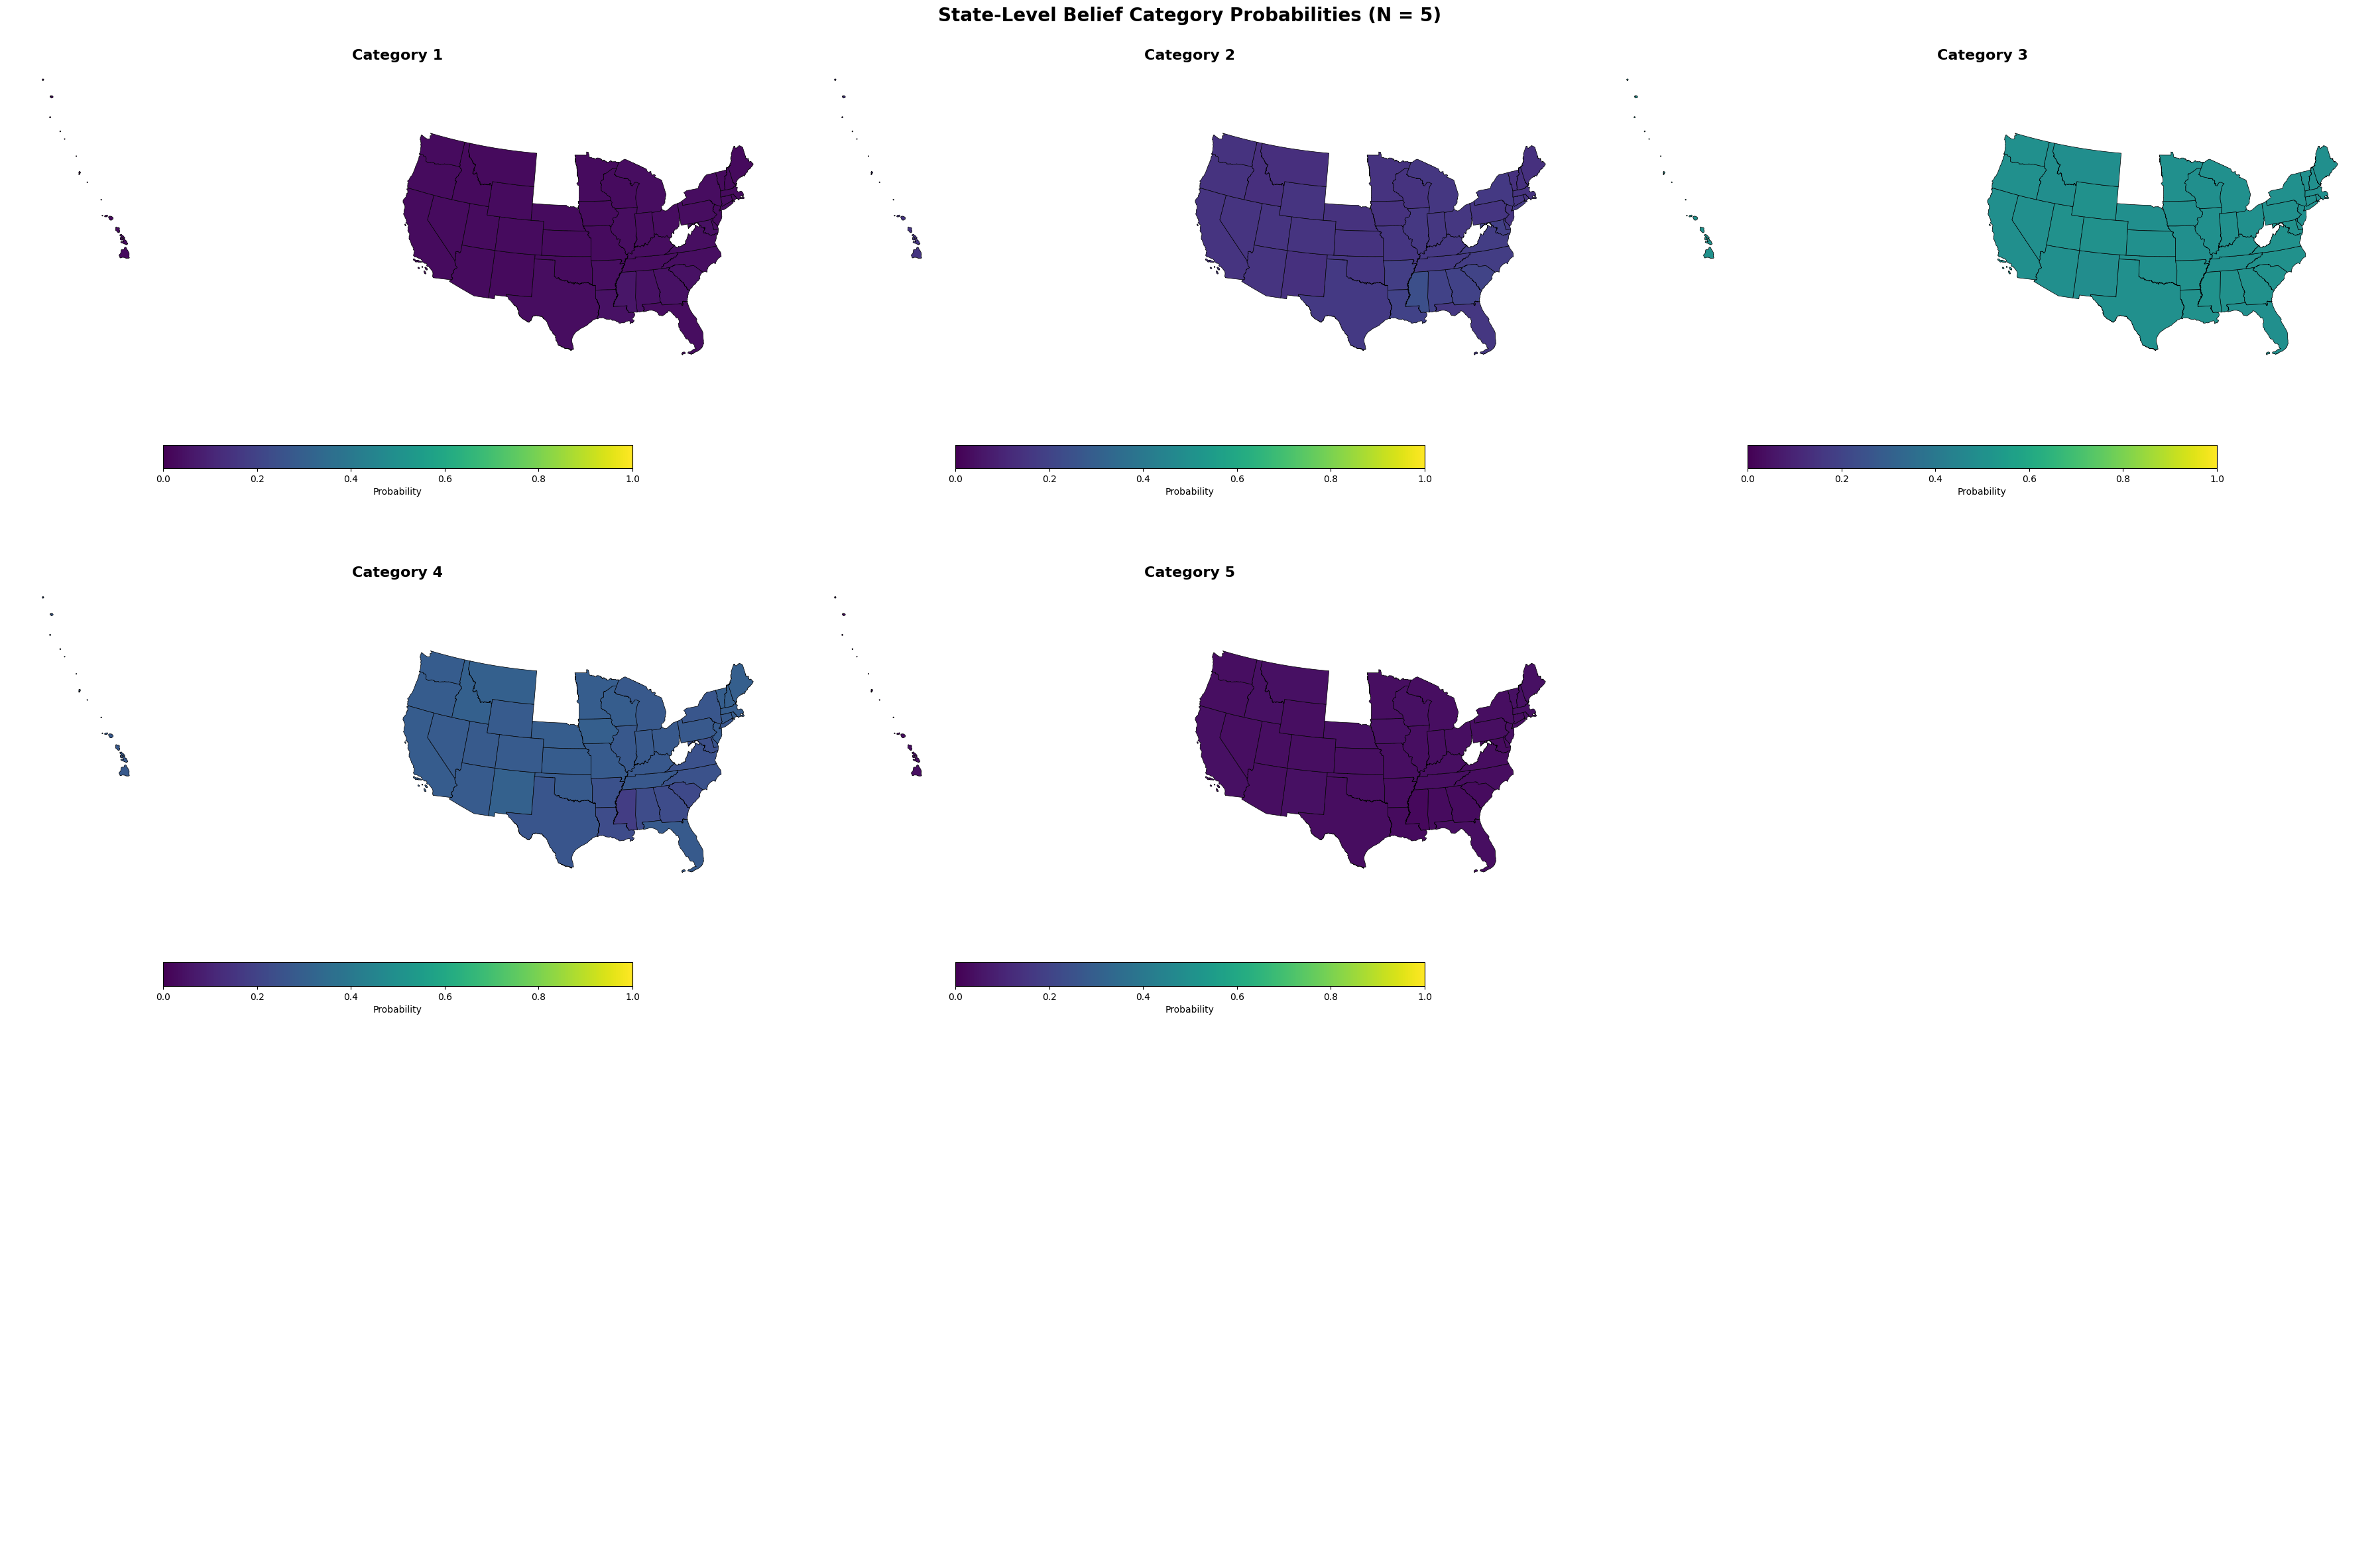

/tmp/ipykernel_1701/209087232.py:150: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap("RdYlGn", n)


 Dominant category map saved to /mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/all_n_white_share/dominant_category_map.png


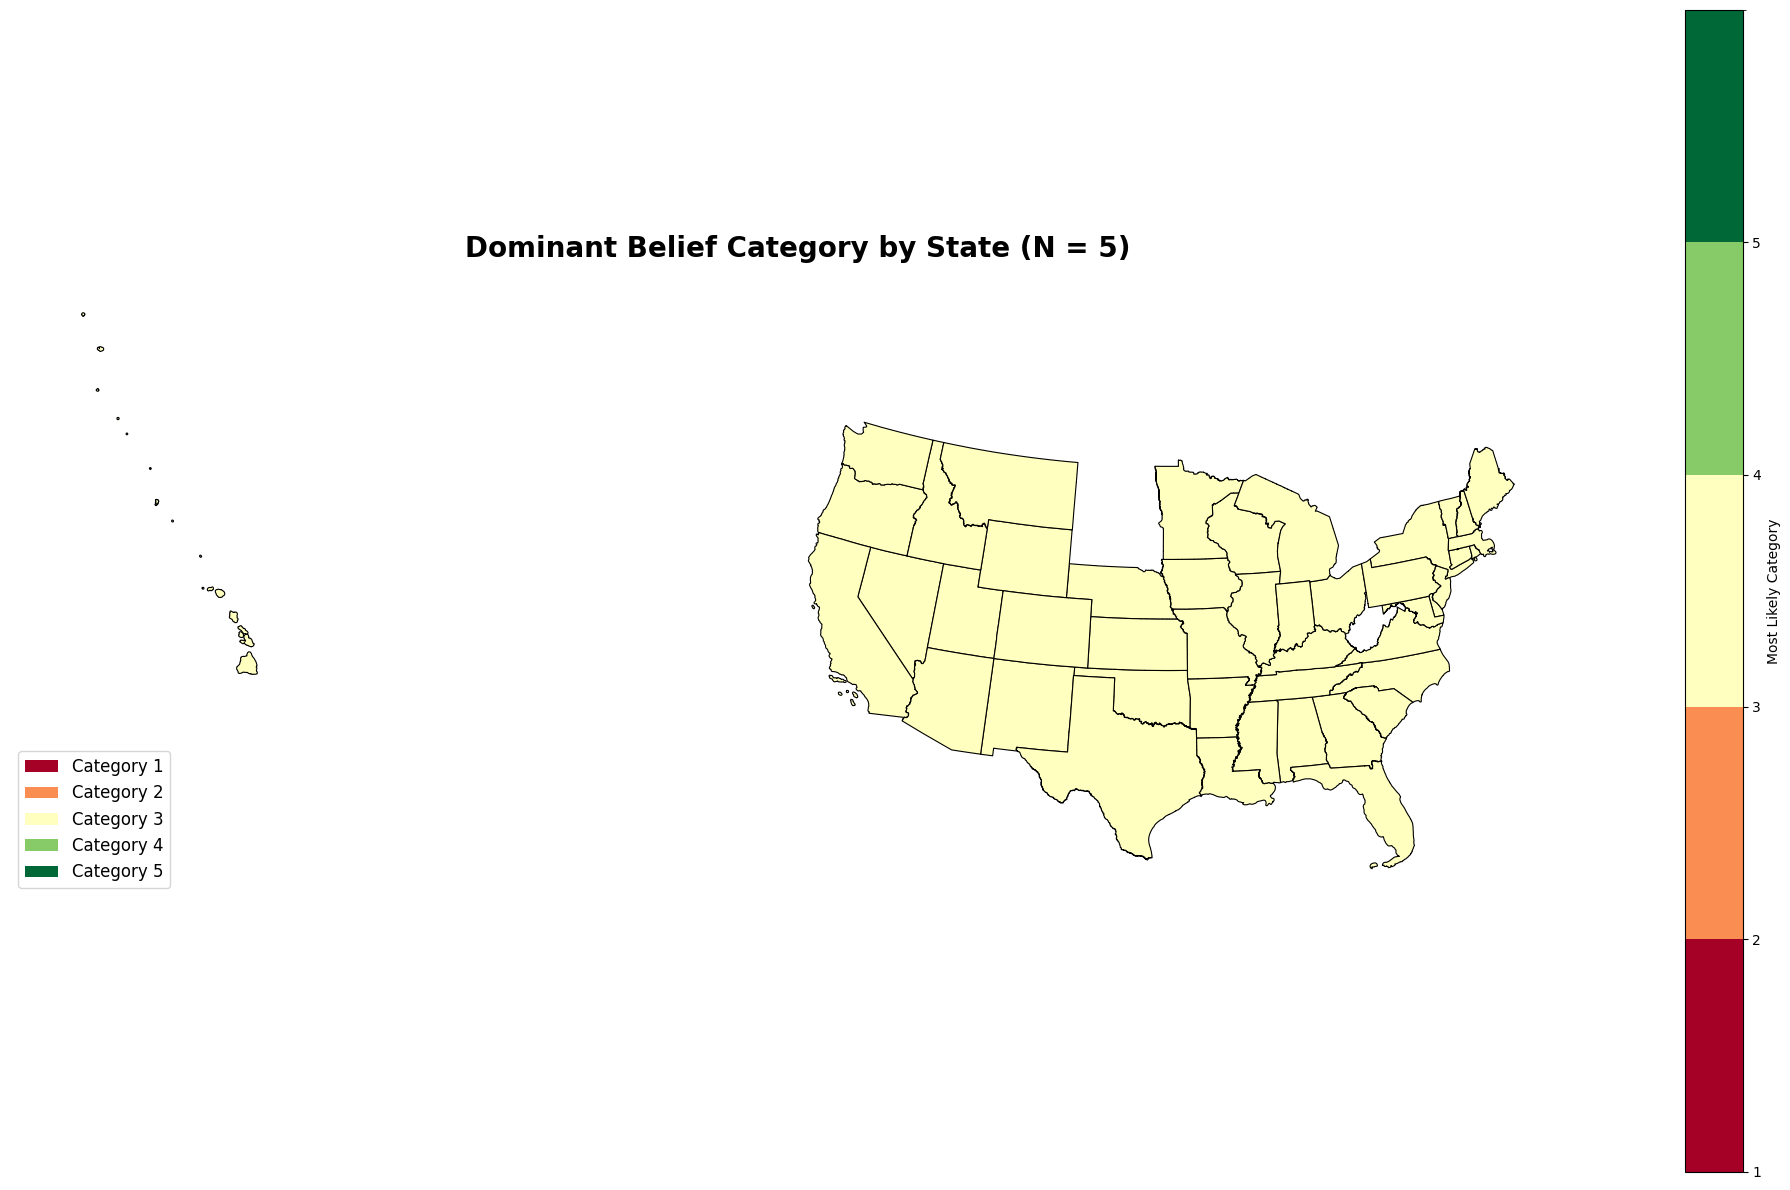


Dominant category by state:
  Category 1: 0 states
    []
  Category 2: 0 states
    []
  Category 3: 47 states
  Category 4: 0 states
    []
  Category 5: 0 states
    []


In [17]:
def aggregate_probabilities_with_uncertainty(strat_frame, state_col='state_simple'):
    
    # Find N_star columns and probability columns
    n_star_cols = [col for col in strat_frame.columns 
                   if col.startswith('N_star.') and col != 'N_star.median']
    prob_cols = [col for col in strat_frame.columns if col.startswith('prob_cat_')]
    
    print(f"  Using {len(n_star_cols)} N_star samples")
    print(f"  Probability columns: {prob_cols}")
    
    state_results = []
    
    for state in strat_frame[state_col].unique():
        state_data = strat_frame[strat_frame[state_col] == state].copy()
        
        # For each N_star sample, compute weighted probabilities
        prob_samples = {prob_col: [] for prob_col in prob_cols}
        
        for n_col in n_star_cols:
            # Normalize weights for this sample
            weights = state_data[n_col] / state_data[n_col].sum()
            
            # Weighted average of each probability
            for prob_col in prob_cols:
                weighted_prob = np.average(state_data[prob_col], weights=weights)
                prob_samples[prob_col].append(weighted_prob)
        
        # Summarize: mean across all N_star samples
        result = {state_col: state}
        for prob_col in prob_cols:
            result[prob_col] = np.mean(prob_samples[prob_col])
            result[f'{prob_col}_lower'] = np.percentile(prob_samples[prob_col], 2.5)
            result[f'{prob_col}_upper'] = np.percentile(prob_samples[prob_col], 97.5)
        
        state_results.append(result)
    
    state_probs = pd.DataFrame(state_results)
    
    print(f" Aggregated {len(state_probs)} states with uncertainty")
    
    # Verify probabilities sum to ~1
    prob_sum = state_probs[prob_cols].sum(axis=1)
    print(f"  Mean probability sum: {prob_sum.mean():.4f} (should be ~1.0)")
    
    return state_probs


state_probs = aggregate_probabilities_with_uncertainty(strat_frame, 'state_simple')

print("\nColumns in state_probs:")
print(state_probs.columns.tolist())

# Visualize
plot_categorical_probabilities(state_probs, shp_path, 'state_simple')
plot_dominant_category(state_probs, shp_path, 'state_simple')

In [ ]:
# List of states with dominant "neither good nor bad"
neutral_states = ['District of Columbia', 'Georgia', 'Hawaii', 'Louisiana', 
                  'Maryland', 'Mississippi', 'New Jersey', 'Virginia']

# Identify probability columns
prob_cols = [c for c in state_probs.columns if c.startswith('prob_cat_')]
print(prob_cols)
# Select relevant states and columns
neutral_probs = state_probs[state_probs['state_simple'].isin(neutral_states)][['state_simple'] + prob_cols]

for idx, row in neutral_probs.iterrows():
    print(f"\nState: {row['state_simple']}")
    for col in prob_cols:
        print(f"  {col}: {row[col]:.4f}")


['prob_cat_1', 'prob_cat_1_lower', 'prob_cat_1_upper', 'prob_cat_2', 'prob_cat_2_lower', 'prob_cat_2_upper', 'prob_cat_3', 'prob_cat_3_lower', 'prob_cat_3_upper', 'prob_cat_4', 'prob_cat_4_lower', 'prob_cat_4_upper', 'prob_cat_5', 'prob_cat_5_lower', 'prob_cat_5_upper']

State: District of Columbia
  prob_cat_1: 0.0594
  prob_cat_1_lower: 0.0594
  prob_cat_1_upper: 0.0594
  prob_cat_2: 0.2024
  prob_cat_2_lower: 0.2023
  prob_cat_2_upper: 0.2024
  prob_cat_3: 0.3572
  prob_cat_3_lower: 0.3571
  prob_cat_3_upper: 0.3573
  prob_cat_4: 0.2616
  prob_cat_4_lower: 0.2615
  prob_cat_4_upper: 0.2616
  prob_cat_5: 0.1195
  prob_cat_5_lower: 0.1195
  prob_cat_5_upper: 0.1195

State: Georgia
  prob_cat_1: 0.0432
  prob_cat_1_lower: 0.0432
  prob_cat_1_upper: 0.0432
  prob_cat_2: 0.1560
  prob_cat_2_lower: 0.1560
  prob_cat_2_upper: 0.1560
  prob_cat_3: 0.3204
  prob_cat_3_lower: 0.3203
  prob_cat_3_upper: 0.3204
  prob_cat_4: 0.3028
  prob_cat_4_lower: 0.3028
  prob_cat_4_upper: 0.3028
  prob_ca